# Cota Parlamentar e produção legislativa: versão revisada (v2)

Este repositório começou como um desafio técnico de um processo seletivo. A primeira versão, que está em [`analise_camara.ipynb`](analise_camara.ipynb), foi a entrega original e não passou para a etapa seguinte. Pedi um retorno à empresa, e a resposta foi esta:

> - A análise estatística ficou um pouco superficial para o perfil da vaga, recomendamos aprofundar mais as investigações e usar séries históricas mais longas (o gráfico de gastos mensais, por exemplo, precisaria contemplar múltiplos anos para sustentar conclusões sobre sazonalidade).
> - O tratamento de erros no código apresentou fragilidades (ex: uso de "except ... break" sem tratamento adequado da exceção).
> - Vale explorar técnicas estatísticas mais avançadas para esse tipo de dado, como por exemplo Índice de Gini ou Curva de Lorenz, que outros candidatos aplicaram com bons resultados.

Este notebook refaz a análise levando essas três críticas a sério. A versão original continua no repositório, sem alterações no código, como registro do que foi entregue.

| Crítica | O que mudou | Onde |
|---|---|---|
| Série curta para falar de sazonalidade | Série mensal de 2018 a 2025 (96 meses, valores corrigidos pelo IPCA), índice sazonal por ano, teste de Friedman e regressão com efeitos fixos de ano e mês | Seção 4 |
| `except ... break` | Exceção própria, novas tentativas com espera crescente, retomada de downloads interrompidos, checagem de integridade e falhas que aparecem em vez de sumir. Um teste com uma API simulada mostra a diferença | Seção 2 |
| Gini e Lorenz | Gini com intervalo de confiança por bootstrap, curvas de Lorenz de gasto e de produção, Gini ano a ano e decomposição de Theil por estado | Seção 5 |
| Análise superficial | Histórico oficial de exercício do mandato para definir quem conta, teste do efeito "use ou perca" em dezembro, verificação fora da amostra com 2026, correlação de Spearman com intervalo de confiança e teste de permutação, quadrantes pela mediana e explicação de por que o "custo por projeto" engana | Seções 4.5, 4.6 e 6 |

Na revisão também apareceram problemas que a avaliação não citou, corrigidos aqui:

1. **Coautoria contada em dobro.** A v1 dava um projeto inteiro a cada coautor. As PECs de 2025 tiveram mediana de 172 autores, então uma única PEC virava 172 "projetos". Aqui cada projeto vale 1, dividido entre seus autores.
2. **Eleição em 2025.** A v1 atribuía o pico de dezembro ao "período eleitoral", mas não houve eleição em 2025. Com vários anos, dá para ver o efeito real das eleições de 2018 e 2022 (Seção 4.4).
3. **Quadrantes pela média.** Com dados muito assimétricos, a média é puxada por poucos deputados, e 262 dos 512 deputados caíam em "ineficiência crítica". Aqui o corte é pela mediana.
4. **Valor do documento × valor reembolsado.** A v1 somava `valorDocumento`. Aqui uso o valor líquido (`vlrLiquido`), que desconta as glosas, ou seja, o que de fato saiu da cota.
5. **Só deputados no cargo hoje.** A v1 partia da lista de deputados em exercício na data da extração. Quem saiu no meio do ano ficava de fora, e quem entrou no meio do ano era comparado com quem ficou o ano todo. Aqui quem conta é definido pelo histórico oficial de exercício do mandato.
6. **MPV e PLV na produção.** Medidas provisórias são do Executivo e PLVs nascem delas. Ficam só PL, PLP, PEC e PDL.

## 1. Configuração

Todos os dados vêm dos arquivos oficiais de dados abertos da Câmara e do Banco Central. Na primeira execução eles são baixados para `Dados/brutos/` (cerca de 190 MB, pasta ignorada pelo git). Nas execuções seguintes, o cache é reaproveitado depois de uma checagem de integridade.

In [1]:
import json
import logging
import sys
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from urllib.parse import parse_qs, urlparse

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from requests.adapters import HTTPAdapter
from scipy import stats
from urllib3.util.retry import Retry

PASTA_DADOS = Path('Dados') / 'brutos'
PASTA_FIGURAS = Path('figuras')
ANOS = list(range(2018, 2026))   # 8 anos completos; 2026 ainda recebe notas (prazo de 90 dias)
ANO_FOCO = 2025
TIPOS_PROJETO = ['PL', 'PLP', 'PEC', 'PDL']
SEMENTE = 42
N_BOOTSTRAP = 2000

logging.basicConfig(stream=sys.stdout, level=logging.INFO, format='%(levelname)s: %(message)s', force=True)
log = logging.getLogger('camara')
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

# Tema escuro com cores neon, o mesmo da v1: ciano, rosa e verde sobre fundo #1e1e1e.
CIANO, ROSA, VERDE = '#00e5ff', '#ff0055', '#39ff14'
TINTA, TINTA_2, CINZA, GRADE, FUNDO = 'white', '#cccccc', '#8a8a8a', '#444444', '#1e1e1e'
plt.rcParams.update(plt.rcParamsDefault)
plt.style.use('dark_background')
plt.rcParams.update({
    'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'savefig.facecolor': FUNDO,
    'axes.edgecolor': GRADE, 'axes.labelcolor': TINTA, 'axes.titlecolor': TINTA,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 15,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linestyle': '--', 'grid.linewidth': 0.5, 'grid.alpha': 0.7,
    'xtick.color': TINTA, 'ytick.color': TINTA, 'text.color': TINTA,
    'font.size': 10.5, 'lines.linewidth': 2.5, 'figure.dpi': 110,
    'legend.frameon': True, 'legend.facecolor': FUNDO, 'legend.edgecolor': 'white',
})
MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
reais_mi = mtick.FuncFormatter(lambda v, _: f'R$ {v / 1e6:.0f} mi')
reais_mil = mtick.FuncFormatter(lambda v, _: f'R$ {v / 1e3:.0f} mil')


def salvar(fig, nome):
    """Salva a figura em figuras/ (usadas no README) e mostra no notebook."""
    PASTA_FIGURAS.mkdir(exist_ok=True)
    fig.savefig(PASTA_FIGURAS / f'{nome}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 2. Extração com tratamento de erros

### 2.1 O problema da versão original

Na v1, a paginação da API era assim:

```python
while True:
    try:
        resposta = requests.get(url, params=params, timeout=10)
        resposta.raise_for_status()
        dados = resposta.json().get('dados', [])
        if not dados:
            break
        ...
        pagina += 1
    except requests.exceptions.RequestException:
        break
```

Se a página 3 de um deputado desse *timeout* ou voltasse com erro 503, o `except` encerrava o laço e a função devolvia só as páginas 1 e 2 como se fossem tudo. Nenhuma mensagem, nenhum registro, e o deputado entrava na análise com gasto menor do que o real. O pipeline "funcionava", mas não havia como saber se os dados estavam completos.

### 2.2 O que mudou

- **Novas tentativas antes de desistir.** Uma `requests.Session` com `Retry` tenta de novo erros de conexão e respostas 429/5xx, com espera crescente (1 s, 2 s, 4 s...) e respeitando o cabeçalho `Retry-After`.
- **Erro que não some.** Se uma página ainda falhar depois das novas tentativas, a função levanta `ExtracaoIncompletaError` dizendo qual página falhou e quantos itens já tinham vindo. Ela não devolve um resultado parcial como se fosse completo.
- **Falhas em lote ficam registradas.** Quando vários deputados são extraídos em paralelo, a falha de um não derruba os outros, mas ela fica num dicionário `falhas` com o motivo, e o log avisa quantos precisam ser reprocessados.
- **Downloads grandes retomam de onde pararam.** O servidor da Câmara costuma fechar a conexão no meio dos arquivos maiores (aconteceu durante esta revisão: o arquivo de proposições parou em 21 de 90 MB). O download vai para um arquivo `.parte`, retoma com o cabeçalho `Range` e só ganha o nome final quando o tamanho bate com o anunciado pelo servidor.
- **O cache é conferido antes de ser usado.** Zips passam por `testzip()`, CSVs precisam terminar em quebra de linha e o JSON precisa ser válido. Um arquivo corrompido é baixado de novo em vez de quebrar a análise mais à frente com um erro difícil de entender.
- **Exceções específicas.** Só são capturadas exceções que o código sabe tratar (`requests.RequestException`, `zipfile.BadZipFile`, `json.JSONDecodeError`). Erros de programação continuam aparecendo normalmente.

### 2.3 Por que arquivos em lote em vez da API

A v1 levava cerca de 5,7 minutos para extrair um único ano pela API, com mais de 500 deputados e várias páginas cada. Para oito anos seriam milhares de requisições. A Câmara publica os mesmos dados em arquivos anuais, com um arquivo por ano, que incluem campos que a API por deputado não traz com facilidade, como o valor líquido e a lista completa de coautores.

A API continua sendo usada onde ela é a única fonte: o **histórico de exercício do mandato** de cada deputado (posse, licença, reassunção, renúncia), na Seção 5. É ali que as funções abaixo trabalham com dados reais.

In [2]:
class ExtracaoIncompletaError(RuntimeError):
    """Os dados não puderam ser obtidos por completo. Melhor parar do que seguir com dados parciais."""


def criar_sessao(tentativas=5):
    """Sessão HTTP que tenta de novo erros transitórios, com espera crescente entre as tentativas."""
    retry = Retry(
        total=tentativas, connect=tentativas, read=tentativas, status=tentativas,
        backoff_factor=1.0, status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=frozenset({'GET', 'HEAD'}), respect_retry_after_header=True,
        raise_on_status=False,  # depois da última tentativa, quem decide é o raise_for_status()
    )
    sessao = requests.Session()
    adaptador = HTTPAdapter(max_retries=retry)
    sessao.mount('https://', adaptador)
    sessao.mount('http://', adaptador)
    return sessao


def paginar_api(sessao, url, params=None, timeout=30):
    """Percorre todas as páginas de um endpoint da API v2 da Câmara.

    Segue o link 'next' devolvido pela própria API em vez de adivinhar o fim pelo tamanho
    da página. Se uma página falhar mesmo depois das novas tentativas da sessão, levanta
    ExtracaoIncompletaError em vez de devolver só o que veio antes dela.
    """
    itens, pagina, proxima = [], 1, url
    while proxima:
        try:
            resposta = sessao.get(proxima, params=params if pagina == 1 else None, timeout=timeout)
            resposta.raise_for_status()
            corpo = resposta.json()
        except (requests.RequestException, ValueError) as erro:   # ValueError cobre JSON inválido
            raise ExtracaoIncompletaError(
                f'{url}: falha na página {pagina} depois de {len(itens)} itens ({erro})'
            ) from erro
        itens.extend(corpo.get('dados', []))
        proxima = next((link['href'] for link in corpo.get('links', []) if link.get('rel') == 'next'), None)
        pagina += 1
    return itens


def extrair_em_paralelo(ids, montar_url, params, fabrica_sessao=criar_sessao, max_workers=8):
    """Roda paginar_api para vários deputados. A falha de um não derruba os outros, mas fica registrada."""
    resultados, falhas = {}, {}
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futuros = {executor.submit(paginar_api, fabrica_sessao(), montar_url(id_), params): id_ for id_ in ids}
        for futuro in as_completed(futuros):
            id_ = futuros[futuro]
            try:
                resultados[id_] = futuro.result()
            except ExtracaoIncompletaError as erro:
                falhas[id_] = str(erro)
    if falhas:
        log.warning('%d de %d deputados com extração incompleta; reprocesse-os antes de analisar',
                    len(falhas), len(ids))
    return resultados, falhas

### 2.4 Teste: o que cada versão faz quando a API falha

Uma API simulada imita `/deputados/{id}/despesas` com 250 despesas por deputado, 100 por página. Para o deputado 2, a página 2 sempre responde 503, como aconteceria depois que as novas tentativas se esgotam. A função `extrair_despesas_original` reproduz a lógica da v1.

In [3]:
class RespostaFalsa:
    def __init__(self, status, corpo=None):
        self.status_code, self._corpo = status, corpo or {}

    def raise_for_status(self):
        if self.status_code >= 400:
            raise requests.HTTPError(f'{self.status_code} Service Unavailable', response=self)

    def json(self):
        return self._corpo


class ApiFalsa:
    """Imita /deputados/{id}/despesas: 250 itens por deputado, 100 por página.
    Para cada deputado em `falha_na_pagina`, aquela página sempre responde 503."""

    def __init__(self, falha_na_pagina=None, total=250):
        self.falha_na_pagina, self.total = falha_na_pagina or {}, total

    def get(self, url, params=None, timeout=None):
        partes = urlparse(url)
        consulta = {k: v[0] for k, v in parse_qs(partes.query).items()}
        consulta.update({k: str(v) for k, v in (params or {}).items()})
        id_dep = int(partes.path.split('/')[-2])
        pagina, itens = int(consulta.get('pagina', 1)), int(consulta.get('itens', 100))
        if self.falha_na_pagina.get(id_dep) == pagina:
            return RespostaFalsa(503)
        inicio = (pagina - 1) * itens
        dados = [{'id_despesa': i} for i in range(inicio, min(inicio + itens, self.total))]
        links = []
        if inicio + itens < self.total:
            links.append({'rel': 'next',
                          'href': f'{partes.scheme}://{partes.netloc}{partes.path}?pagina={pagina + 1}&itens={itens}'})
        return RespostaFalsa(200, {'dados': dados, 'links': links})


def extrair_despesas_original(sessao, url):
    """Mesma lógica da v1, só com a sessão injetada para o teste."""
    despesas, pagina = [], 1
    while True:
        try:
            resposta = sessao.get(url, params={'itens': 100, 'pagina': pagina}, timeout=10)
            resposta.raise_for_status()
            dados = resposta.json().get('dados', [])
            if not dados:
                break
            despesas.extend(dados)
            if len(dados) < 100:
                break
            pagina += 1
        except requests.exceptions.RequestException:
            break
    return despesas


api = ApiFalsa(falha_na_pagina={2: 2})
montar_url = lambda id_: f'https://api.exemplo/deputados/{id_}/despesas'

antigo = {id_: len(extrair_despesas_original(api, montar_url(id_))) for id_ in (1, 2, 3)}
print('v1 (except ... break) - despesas por deputado:', antigo)
print('    O deputado 2 voltou com 100 de 250 despesas e nada avisou.\n')

resultados, falhas = extrair_em_paralelo([1, 2, 3], montar_url, {'itens': 100}, fabrica_sessao=lambda: api)
print('v2 - extraídos por completo:', {k: len(v) for k, v in sorted(resultados.items())})
print('v2 - falhas registradas:', falhas)

assert antigo[2] == 100 and 2 in falhas and all(len(v) == 250 for v in resultados.values())

v1 (except ... break) - despesas por deputado: {1: 250, 2: 100, 3: 250}
    O deputado 2 voltou com 100 de 250 despesas e nada avisou.



v2 - extraídos por completo: {1: 250, 3: 250}
v2 - falhas registradas: {2: 'https://api.exemplo/deputados/2/despesas: falha na página 2 depois de 100 itens (503 Service Unavailable)'}


### 2.5 Download dos arquivos oficiais

| Arquivo | Conteúdo |
|---|---|
| `Ano-AAAA.csv.zip` (2018 a 2025) | Todos os lançamentos da Cota para o Exercício da Atividade Parlamentar (CEAP) no ano |
| `proposicoes-2025.csv` | Proposições de 2025, com o tipo (PL, PEC...) |
| `proposicoesAutores-2025.csv` | Todos os autores e coautores de cada proposição |
| `ipca_433.json` | IPCA mensal (série 433 do Banco Central), para corrigir a inflação |

A política de falha é diferente da extração por deputado: aqui todos os arquivos são necessários. Então o código tenta todos, junta todas as falhas e, se houver alguma, para com a lista completa. Ele não segue com metade dos anos.

In [4]:
def baixar_arquivo(sessao, url, destino, tentativas=5, timeout=120):
    """Baixa um arquivo grande, retomando de onde parou se a conexão cair no meio.

    O download vai para '<nome>.parte' e só ganha o nome final quando o tamanho
    confere com o Content-Length anunciado pelo servidor.
    """
    destino.parent.mkdir(parents=True, exist_ok=True)
    parcial = destino.with_name(destino.name + '.parte')
    for tentativa in range(1, tentativas + 1):
        inicio = parcial.stat().st_size if parcial.exists() else 0
        cabecalhos = {'Range': f'bytes={inicio}-'} if inicio else {}
        esperado = None
        try:
            with sessao.get(url, headers=cabecalhos, stream=True, timeout=timeout) as resposta:
                if resposta.status_code == 416:      # não há mais bytes a enviar
                    parcial.replace(destino)
                    return destino
                resposta.raise_for_status()
                if resposta.status_code != 206:      # o servidor ignorou o Range: recomeça do zero
                    inicio = 0
                restante = resposta.headers.get('Content-Length')
                if restante and 'Content-Encoding' not in resposta.headers:
                    esperado = inicio + int(restante)
                with open(parcial, 'ab' if inicio else 'wb') as arquivo:
                    for bloco in resposta.iter_content(chunk_size=1 << 20):
                        arquivo.write(bloco)
        except requests.RequestException as erro:
            log.warning('%s: tentativa %d/%d interrompida (%s)', destino.name, tentativa, tentativas,
                        type(erro).__name__)
        else:
            obtido = parcial.stat().st_size
            if esperado is None or obtido == esperado:
                parcial.replace(destino)
                return destino
            log.warning('%s: recebidos %d de %d bytes; retomando', destino.name, obtido, esperado)
            if obtido > esperado:                    # algo se misturou: recomeça do zero
                parcial.unlink()
        time.sleep(min(2 ** tentativa, 30))
    raise ExtracaoIncompletaError(f'{url}: download incompleto depois de {tentativas} tentativas')


def validar_arquivo(caminho):
    """Confere se um arquivo está inteiro antes de usá-lo."""
    if caminho.stat().st_size == 0:
        raise ExtracaoIncompletaError(f'{caminho.name}: arquivo vazio')
    if caminho.suffix == '.zip':
        try:
            with zipfile.ZipFile(caminho) as pacote:
                corrompido = pacote.testzip()
        except zipfile.BadZipFile as erro:
            raise ExtracaoIncompletaError(f'{caminho.name}: zip inválido') from erro
        if corrompido:
            raise ExtracaoIncompletaError(f'{caminho.name}: {corrompido} corrompido dentro do zip')
    elif caminho.suffix == '.csv':
        with open(caminho, 'rb') as arquivo:
            arquivo.seek(-1, 2)
            if arquivo.read(1) != b'\n':
                raise ExtracaoIncompletaError(f'{caminho.name}: termina no meio de uma linha (truncado)')
    elif caminho.suffix == '.json':
        try:
            conteudo = json.loads(caminho.read_text(encoding='utf-8'))
        except json.JSONDecodeError as erro:
            raise ExtracaoIncompletaError(f'{caminho.name}: JSON inválido') from erro
        if not conteudo:
            raise ExtracaoIncompletaError(f'{caminho.name}: JSON sem dados')


def garantir_arquivos(arquivos, sessao):
    """Usa o cache quando ele está íntegro e baixa o resto. Se algo falhar, para no fim com a lista completa."""
    falhas, linhas = {}, []
    for nome, url in arquivos.items():
        destino, origem = PASTA_DADOS / nome, 'cache'
        try:
            if destino.exists():
                try:
                    validar_arquivo(destino)
                except ExtracaoIncompletaError as erro:
                    log.warning('%s; baixando de novo', erro)
                    destino.unlink()
            if not destino.exists():
                origem = 'download'
                baixar_arquivo(sessao, url, destino)
                validar_arquivo(destino)
        except ExtracaoIncompletaError as erro:
            falhas[nome] = str(erro)
            continue
        linhas.append({'arquivo': nome, 'origem': origem, 'tamanho_MB': destino.stat().st_size / 1e6})
    if falhas:
        raise ExtracaoIncompletaError(
            'Arquivos que não puderam ser obtidos:\n' + '\n'.join(f'  - {k}: {v}' for k, v in falhas.items()))
    return pd.DataFrame(linhas)


BASE_CEAP = 'https://www.camara.leg.br/cotas'
BASE_ARQUIVOS = 'https://dadosabertos.camara.leg.br/arquivos'
ARQUIVOS = {f'Ano-{ano}.csv.zip': f'{BASE_CEAP}/Ano-{ano}.csv.zip' for ano in ANOS}
ARQUIVOS |= {
    f'proposicoes-{ANO_FOCO}.csv': f'{BASE_ARQUIVOS}/proposicoes/csv/proposicoes-{ANO_FOCO}.csv',
    f'proposicoesAutores-{ANO_FOCO}.csv': f'{BASE_ARQUIVOS}/proposicoesAutores/csv/proposicoesAutores-{ANO_FOCO}.csv',
    'ipca_433.json': ('https://api.bcb.gov.br/dados/serie/bcdata.sgs.433/dados?formato=json'
                      f'&dataInicial=01/01/{ANOS[0]}&dataFinal=31/12/{ANOS[-1]}'),
}

inicio = time.perf_counter()
inventario = garantir_arquivos(ARQUIVOS, criar_sessao())
print(f'{len(inventario)} arquivos prontos em {time.perf_counter() - inicio:.1f} s')
display(inventario)

11 arquivos prontos em 0.8 s


,arquivo,origem,tamanho_MB
0,Ano-2018.csv.zip,cache,8.86
1,Ano-2019.csv.zip,cache,9.09
2,Ano-2020.csv.zip,cache,5.37
3,Ano-2021.csv.zip,cache,6.85
4,Ano-2022.csv.zip,cache,6.64
5,Ano-2023.csv.zip,cache,7.52
6,Ano-2024.csv.zip,cache,7.50
7,Ano-2025.csv.zip,cache,6.90
8,proposicoes-2025.csv,cache,90.20
9,proposicoesAutores-2025.csv,cache,38.94


## 3. Carga e limpeza da Cota Parlamentar (2018 a 2025)

Decisões tomadas nesta etapa:

- **Valor:** `vlrLiquido`, o valor do documento menos a glosa (a parte que a Câmara não reembolsou). O código confere essa relação linha a linha.
- **Mês:** `numMes`/`numAno`, o mês ao qual a despesa foi atribuída na cota. A data de emissão do documento falta em cerca de 3% das linhas e, em cerca de 9%, cai em outro mês. Esse é um dos motivos de a v1, que usava a data do documento, ter encontrado um pico em dezembro de 2025 que não aparece aqui.
- **Quem entra:** só lançamentos com identificador de deputado. Lideranças partidárias também usam a cota, mas não são pessoas e ficam fora.
- **Valores negativos:** aparecem quase só em passagens aéreas (pelo padrão, créditos de bilhetes cancelados ou remarcados; o arquivo não explica) e em "complementação do auxílio-moradia", que nesta base é sempre negativa. Eles ficam na soma, que é o valor líquido do mês.
- **Erros de tipo param a carga.** A conversão numérica usa `errors='raise'`, e não `errors='coerce'` como na v1. Um valor que não é número é um problema no arquivo e precisa aparecer, não virar `NaN` em silêncio.

In [5]:
COLUNAS_CEAP = {
    'ideCadastro': 'id_deputado', 'txNomeParlamentar': 'nome', 'sgUF': 'uf', 'sgPartido': 'partido',
    'txtDescricao': 'categoria_original', 'txtCNPJCPF': 'fornecedor_doc', 'datEmissao': 'data_emissao',
    'vlrDocumento': 'valor_documento', 'vlrGlosa': 'valor_glosa', 'vlrLiquido': 'valor_liquido',
    'numMes': 'mes', 'numAno': 'ano',
}
ROTULOS_CATEGORIA = {
    'DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR': 'Divulgação da atividade parlamentar',
    'LOCAÇÃO OU FRETAMENTO DE VEÍCULOS AUTOMOTORES': 'Locação de veículos',
    'MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE PARLAMENTAR': 'Escritório de apoio',
    'COMBUSTÍVEIS E LUBRIFICANTES': 'Combustíveis',
    'CONSULTORIAS, PESQUISAS E TRABALHOS TÉCNICOS': 'Consultorias e pesquisas',
    'SERVIÇO DE TÁXI, PEDÁGIO E ESTACIONAMENTO': 'Táxi, pedágio e estacionamento',
    'FORNECIMENTO DE ALIMENTAÇÃO DO PARLAMENTAR': 'Alimentação',
    'HOSPEDAGEM ,EXCETO DO PARLAMENTAR NO DISTRITO FEDERAL': 'Hospedagem',
    'TELEFONIA': 'Telefonia',
    'SERVIÇO DE SEGURANÇA PRESTADO POR EMPRESA ESPECIALIZADA': 'Segurança',
    'COMPLEMENTAÇÃO DO AUXÍLIO-MORADIA': 'Complementação do auxílio-moradia',
}


def rotular_categoria(texto):
    texto = texto.strip().rstrip('.').strip()
    if texto.startswith('PASSAGEM AÉREA'):
        return 'Passagens aéreas'
    return ROTULOS_CATEGORIA.get(texto, texto.capitalize())


def ler_ceap(ano):
    with zipfile.ZipFile(PASTA_DADOS / f'Ano-{ano}.csv.zip') as pacote, pacote.open(pacote.namelist()[0]) as arquivo:
        tabela = pd.read_csv(arquivo, sep=';', encoding='utf-8-sig', usecols=list(COLUNAS_CEAP), dtype=str)
    tabela = tabela.rename(columns=COLUNAS_CEAP)
    for coluna in ['valor_documento', 'valor_glosa', 'valor_liquido']:
        tabela[coluna] = pd.to_numeric(tabela[coluna], errors='raise')
    tabela[['ano', 'mes']] = tabela[['ano', 'mes']].astype(int)
    if (tabela['ano'] != ano).any():
        raise ValueError(f'Ano-{ano}.csv.zip contém lançamentos de outro ano')
    return tabela


ceap_bruto = pd.concat([ler_ceap(ano) for ano in ANOS], ignore_index=True)

confere = (ceap_bruto['valor_documento'] - ceap_bruto['valor_glosa'] - ceap_bruto['valor_liquido']).abs() < 0.01
emissao = pd.to_datetime(ceap_bruto['data_emissao'], errors='coerce')
mesmo_mes = (emissao.dt.year == ceap_bruto['ano']) & (emissao.dt.month == ceap_bruto['mes'])
print(f'{len(ceap_bruto):,} lançamentos de {ANOS[0]} a {ANOS[-1]}')
print(f'valor líquido = documento - glosa em {confere.mean():.1%} das linhas')
print(f'data de emissão ausente em {emissao.isna().mean():.1%}; em outro mês que o da cota em {(~mesmo_mes & emissao.notna()).mean():.1%}')

qualidade = ceap_bruto.groupby('ano').agg(
    lancamentos=('valor_liquido', 'size'),
    deputados=('id_deputado', 'nunique'),
    linhas_de_liderancas=('id_deputado', lambda s: s.isna().sum()),
    linhas_negativas=('valor_liquido', lambda s: (s < 0).sum()),
    liquido_R_mi=('valor_liquido', lambda s: s.sum() / 1e6),
    glosas_R_mi=('valor_glosa', lambda s: s.sum() / 1e6),
)
display(qualidade)

ceap = ceap_bruto[ceap_bruto['id_deputado'].notna()].copy()
ceap['categoria'] = ceap['categoria_original'].map({c: rotular_categoria(c) for c in ceap['categoria_original'].unique()})
ceap['competencia'] = pd.to_datetime(ceap[['ano', 'mes']].rename(columns={'ano': 'year', 'mes': 'month'}).assign(day=1))

negativos = ceap[(ceap['ano'] == ANO_FOCO) & (ceap['valor_liquido'] < 0)]
print(f'\nLançamentos negativos em {ANO_FOCO}, por categoria:')
display(negativos.groupby('categoria')['valor_liquido'].agg(linhas='size', soma='sum').sort_values('soma'))

1,853,096 lançamentos de 2018 a 2025
valor líquido = documento - glosa em 99.6% das linhas
data de emissão ausente em 3.3%; em outro mês que o da cota em 8.7%


,lancamentos,deputados,linhas_de_liderancas,linhas_negativas,liquido_R_mi,glosas_R_mi
ano,,,,,,
2018,293071,555,752,14851,215.20,1.55
2019,289829,804,905,11107,210.93,1.02
2020,167132,540,392,4522,173.31,0.72
2021,218759,564,858,7912,210.08,0.81
2022,209552,554,627,3472,219.49,1.19
2023,232754,788,855,10130,245.53,1.18
2024,232918,582,903,11737,250.38,1.29
2025,209081,562,937,8032,240.35,1.01



Lançamentos negativos em 2025, por categoria:


,linhas,soma
categoria,,
Passagens aéreas,7198,"-8,099,434.21"
Complementação do auxílio-moradia,834,"-1,811,993.18"


O número de deputados passa de 513 todos os anos porque suplentes assumem quando titulares viram ministros ou se licenciam. Em 2019 e 2023 ele chega perto de 800 porque janeiro ainda é da legislatura anterior e a nova toma posse em 1º de fevereiro. Isso importa na Seção 5: comparar o gasto anual de um titular com o de um suplente que ficou dois meses no cargo infla qualquer medida de desigualdade.

In [6]:
with open(PASTA_DADOS / 'ipca_433.json', encoding='utf-8') as arquivo:
    ipca = pd.DataFrame(json.load(arquivo))
ipca['competencia'] = pd.to_datetime(ipca['data'], format='%d/%m/%Y')
ipca['variacao'] = pd.to_numeric(ipca['valor'], errors='raise') / 100
ipca = ipca.set_index('competencia').sort_index()
if len(ipca) != 12 * len(ANOS):
    raise ValueError(f'IPCA com {len(ipca)} meses; esperado {12 * len(ANOS)}')
ipca['indice'] = (1 + ipca['variacao']).cumprod()
ipca['fator_dez'] = ipca['indice'].iloc[-1] / ipca['indice']   # leva cada mês para preços de dez/2025
print(f'Inflação acumulada (IPCA) de jan/{ANOS[0]} a dez/{ANOS[-1]}: {ipca["indice"].iloc[-1] - 1:.1%}')

Inflação acumulada (IPCA) de jan/2018 a dez/2025: 50.6%


## 4. Série histórica e sazonalidade (2018 a 2025)

A v1 olhou só 2025 e concluiu que dezembro era o pico do ano, "relacionado ao calendário eleitoral". Com um ano só não dá para separar o que se repete todo ano do que aconteceu naquele ano. Com oito anos dá.

### 4.1 Gasto mensal, em valores nominais e corrigidos pela inflação

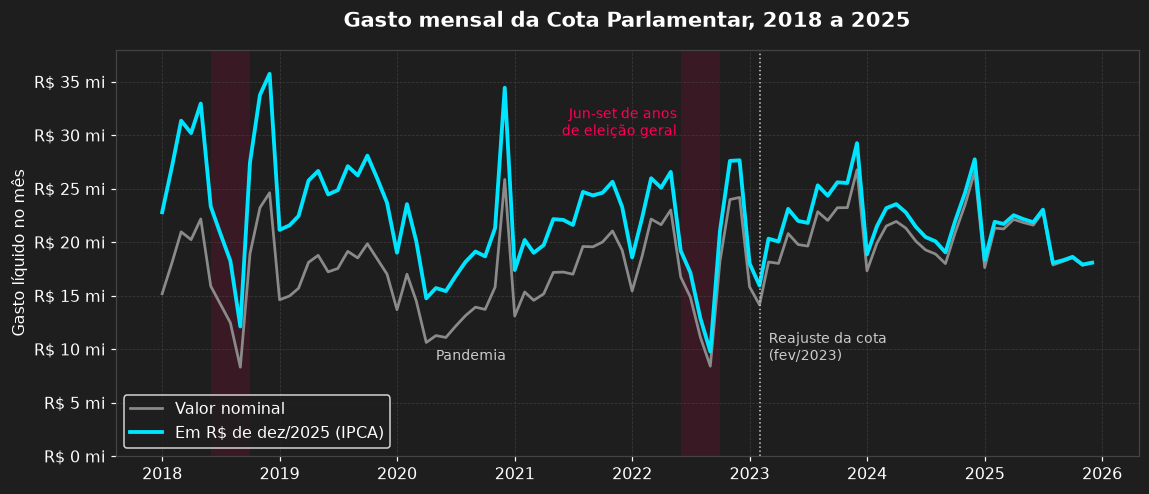

,nominal_R_mi,real_R_mi_dez2025,variacao_real
ano,,,
2018,214.44,316.00,NaN
2019,210.01,298.07,-0.06
2020,172.88,237.20,-0.20
2021,209.16,264.93,0.12
2022,218.58,253.93,-0.04
2023,244.57,271.41,0.07
2024,249.37,265.37,-0.02
2025,239.21,242.64,-0.09


In [7]:
mensal = ceap.groupby('competencia')['valor_liquido'].sum().rename('nominal').to_frame().join(ipca['fator_dez'])
mensal['real'] = mensal['nominal'] * mensal['fator_dez']
if len(mensal) != 12 * len(ANOS):
    raise ValueError('a série mensal tem meses faltando')

fig, ax = plt.subplots(figsize=(12, 4.8))
for ano in (2018, 2022):
    ax.axvspan(pd.Timestamp(ano, 6, 1), pd.Timestamp(ano, 9, 30), color=ROSA, alpha=0.12, lw=0)
ax.plot(mensal.index, mensal['nominal'], color=CINZA, lw=1.8, label='Valor nominal')
ax.plot(mensal.index, mensal['real'], color=CIANO, label='Em R$ de dez/2025 (IPCA)')
ax.axvline(pd.Timestamp(2023, 2, 1), color=TINTA_2, ls=':', lw=1)
ax.annotate('Reajuste da cota\n(fev/2023)', (pd.Timestamp(2023, 2, 1), 9e6), xytext=(6, 0),
            textcoords='offset points', fontsize=9, color=TINTA_2)
ax.annotate('Pandemia', (pd.Timestamp(2020, 5, 1), 9e6), fontsize=9, color=TINTA_2)
ax.annotate('Jun-set de anos\nde eleição geral', (pd.Timestamp(2022, 5, 20), 30e6), fontsize=9, color=ROSA, ha='right')
ax.yaxis.set_major_formatter(reais_mi)
ax.set_ylim(0, 38e6)
ax.set_title('Gasto mensal da Cota Parlamentar, 2018 a 2025')
ax.set_ylabel('Gasto líquido no mês')
ax.legend(loc='lower left')
salvar(fig, '01_serie_mensal')

anual = mensal.groupby(mensal.index.year)[['nominal', 'real']].sum() / 1e6
anual['variacao_real'] = anual['real'].pct_change()
anual.index.name = 'ano'
display(anual.rename(columns={'nominal': 'nominal_R_mi', 'real': 'real_R_mi_dez2025'}))

**Leitura.** Em valores nominais, o gasto subiu de R$ 214 mi (2018) para R$ 239 mi (2025). Corrigido pela inflação, caiu de R$ 316 mi para R$ 243 mi, uma queda real de 23%, mesmo com o reajuste da cota em 2023. Os vales mais fundos são junho a setembro de 2018 e 2022 e o ano de 2020. Os picos de dezembro aparecem na maioria dos anos, mas não em todos.

### 4.2 Índice sazonal: cada mês comparado com a média do próprio ano

Para comparar meses de anos com níveis diferentes (inflação, reajuste da cota, pandemia), cada mês é dividido pela média mensal do seu ano. O valor 1,00 é um mês típico daquele ano, e 1,30 é 30% acima.

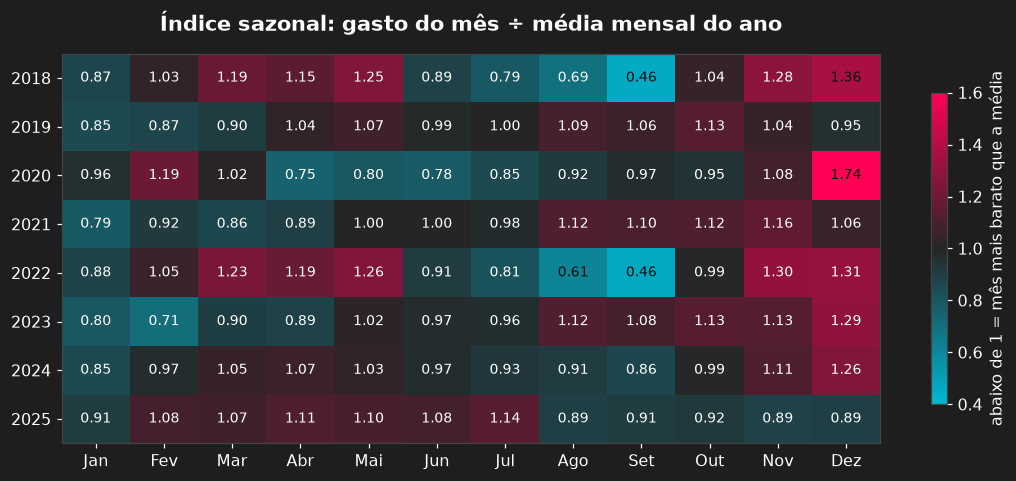

mes,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
mediana,0.86,1.00,1.03,1.05,1.05,0.97,0.95,0.91,0.94,1.02,1.12,1.27
minimo,0.79,0.71,0.86,0.75,0.80,0.78,0.79,0.61,0.46,0.92,0.89,0.89
maximo,0.96,1.19,1.23,1.19,1.26,1.08,1.14,1.12,1.10,1.13,1.30,1.74
anos_acima_da_media,0.00,4.00,5.00,5.00,7.00,2.00,2.00,3.00,3.00,4.00,7.00,6.00


In [8]:
por_mes = mensal['real'].groupby([mensal.index.year, mensal.index.month]).sum().unstack()
indice = por_mes.div(por_mes.mean(axis=1), axis=0)
indice.index.name, indice.columns.name = 'ano', 'mes'

divergente = LinearSegmentedColormap.from_list('div', ['#00b8d4', '#262626', '#ff0055'])
fig, ax = plt.subplots(figsize=(12, 4.6))
imagem = ax.imshow(indice.values, cmap=divergente, norm=TwoSlopeNorm(vcenter=1, vmin=0.4, vmax=1.6), aspect='auto')
for i, ano in enumerate(indice.index):
    for j in range(12):
        valor = indice.iloc[i, j]
        ax.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=9,
                color='#0b0b0b' if abs(valor - 1) > 0.35 else TINTA)
ax.set_xticks(range(12), MESES)
ax.set_yticks(range(len(indice)), indice.index)
ax.grid(False)
ax.set_title('Índice sazonal: gasto do mês ÷ média mensal do ano')
fig.colorbar(imagem, ax=ax, shrink=0.8, label='abaixo de 1 = mês mais barato que a média')
salvar(fig, '02_indice_sazonal')

resumo_mes = pd.DataFrame({
    'mediana': indice.median(),
    'minimo': indice.min(),
    'maximo': indice.max(),
    'anos_acima_da_media': (indice > 1).sum(),
}).rename(index=dict(enumerate(MESES, start=1)))
display(resumo_mes.T)

**Leitura.** Janeiro ficou abaixo da média do ano em todos os 8 anos: é mês de recesso e, em 2019 e 2023, de troca de legislatura. Maio e novembro ficaram acima em 7 de 8 anos, e dezembro em 6 de 8. **Dezembro de 2025, o único ano que a v1 analisou, foi um dos dois anos em que dezembro ficou abaixo da média (0,89).** A v1 encontrou pico em dezembro usando a data do documento e os dados da API de julho de 2026, e não consegui reproduzir exatamente aquele número com os arquivos atuais. Mas o ponto da crítica se confirma: com um ano só, não havia como saber se o padrão se repete, e o ano escolhido era justamente uma exceção.

### 4.3 Os meses diferem de forma consistente? (teste de Friedman)

O teste de Friedman é a versão não paramétrica da ANOVA de medidas repetidas. Cada ano é um "bloco" e cada mês, um "tratamento". A pergunta é se a ordem dos meses dentro de cada ano se repete mais do que o acaso explicaria. O W de Kendall mede o tamanho do efeito, de 0 (nenhuma concordância entre os anos) a 1 (todos os anos com a mesma ordem).

In [9]:
def friedman(tabela):
    resultado = stats.friedmanchisquare(*[tabela[m] for m in tabela.columns])
    n, k = tabela.shape
    return resultado.statistic, resultado.pvalue, resultado.statistic / (n * (k - 1))


cenarios = {
    'Todos os anos (2018-2025)': indice,
    'Sem anos de eleição geral (2018, 2022)': indice.drop([2018, 2022]),
    'Sem eleição geral e sem 2020 (pandemia)': indice.drop([2018, 2020, 2022]),
}
tabela_friedman = pd.DataFrame(
    [(nome, len(t), *friedman(t)) for nome, t in cenarios.items()],
    columns=['cenario', 'anos', 'qui_quadrado', 'p_valor', 'W_de_Kendall'],
).set_index('cenario')
display(tabela_friedman.style.format({'qui_quadrado': '{:.1f}', 'p_valor': '{:.2g}', 'W_de_Kendall': '{:.2f}'}))

,anos,qui_quadrado,p_valor,W_de_Kendall
cenario,,,,
Todos os anos (2018-2025),8,23.7,0.014,0.27
"Sem anos de eleição geral (2018, 2022)",6,14.6,0.2,0.22
Sem eleição geral e sem 2020 (pandemia),5,16.9,0.11,0.31


**Leitura.** Com os 8 anos, a ordem dos meses se repete mais do que o acaso explicaria (p = 0,014), mas a concordância entre os anos é moderada (W = 0,27). Sem os anos de eleição geral, o teste deixa de ser significativo (p = 0,20 com 6 anos). Parte do padrão vem das eleições, e com 5 ou 6 anos o teste tem pouca potência para efeitos menores. A regressão a seguir separa as duas coisas.

### 4.4 Quanto vale cada mês, descontando ano, eleição e pandemia (regressão com efeitos fixos)

O índice da Seção 4.2 mistura três coisas: o padrão que se repete todo ano, o efeito das eleições gerais e o choque da pandemia. Para separar, uso uma regressão do log do gasto mensal (corrigido pela inflação) com:

- **efeito fixo de ano**, que absorve o nível de cada ano (inflação residual, reajuste da cota, troca de legislatura);
- **efeito fixo de mês**, o padrão sazonal que se repete;
- **`janela_eleitoral`**, igual a 1 de junho a setembro de 2018 e 2022. O Ato da Mesa nº 43/2009 (art. 2º, XII) proíbe usar a cota com divulgação da atividade parlamentar nos 120 dias antes da eleição, para quem for candidato;
- **`pandemia`**, igual a 1 de abril a novembro de 2020.

Os erros padrão são HAC (Newey-West, 3 defasagens), porque os resíduos de meses vizinhos tendem a ser correlacionados. Os efeitos de mês aparecem em relação ao mês médio, com intervalo de confiança de 95%.

Jun-set em ano de eleição geral: -41.3% (IC 95%: -48.0% a -33.7%; p = 7e-18)
Abr-nov de 2020: -31.8% (IC 95%: -40.6% a -21.8%; p = 4e-08)
R² = 0.72 com 96 meses


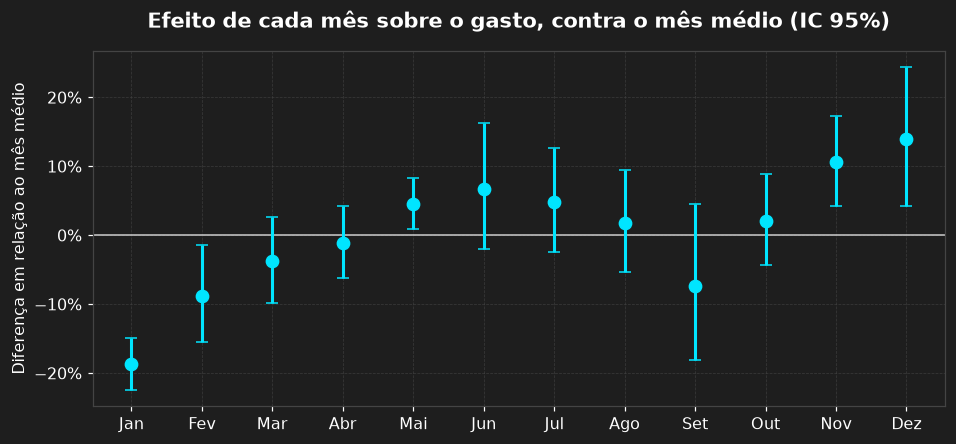

,efeito,ic_baixo,ic_alto,p_valor
Jan,-18.7%,-22.5%,-14.8%,3.7e-18
Fev,-8.8%,-15.5%,-1.5%,0.019
Mar,-3.8%,-9.9%,+2.7%,0.25
Abr,-1.1%,-6.2%,+4.2%,0.67
Mai,+4.6%,+0.9%,+8.4%,0.014
Jun,+6.8%,-2.0%,+16.2%,0.13
Jul,+4.8%,-2.5%,+12.6%,0.2
Ago,+1.8%,-5.4%,+9.5%,0.63
Set,-7.4%,-18.0%,+4.6%,0.21
Out,+2.1%,-4.3%,+8.8%,0.53


In [10]:
painel = mensal.reset_index()
painel['ano'] = painel['competencia'].dt.year
painel['mes'] = painel['competencia'].dt.month
painel['log_real'] = np.log(painel['real'])
painel['janela_eleitoral'] = (painel['ano'].isin([2018, 2022]) & painel['mes'].between(6, 9)).astype(int)
painel['pandemia'] = ((painel['ano'] == 2020) & painel['mes'].between(4, 11)).astype(int)

modelo = smf.ols('log_real ~ C(ano) + C(mes) + janela_eleitoral + pandemia', data=painel).fit(
    cov_type='HAC', cov_kwds={'maxlags': 3})


def efeito_percentual(nome):
    beta, (baixo, alto) = modelo.params[nome], modelo.conf_int().loc[nome]
    return np.exp(beta) - 1, np.exp(baixo) - 1, np.exp(alto) - 1, modelo.pvalues[nome]


for nome, rotulo in [('janela_eleitoral', 'Jun-set em ano de eleição geral'), ('pandemia', 'Abr-nov de 2020')]:
    efeito, baixo, alto = efeito_percentual(nome)[:3]
    print(f'{rotulo}: {efeito:+.1%} (IC 95%: {baixo:+.1%} a {alto:+.1%}; p = {modelo.pvalues[nome]:.1g})')
print(f'R² = {modelo.rsquared:.2f} com {int(modelo.nobs)} meses')

# Efeito de cada mês contra o mês médio: contraste beta_m - média(beta_1..beta_12), com beta_jan = 0.
nomes = modelo.params.index
contraste = np.zeros((12, len(nomes)))
for m in range(1, 13):
    for k in range(2, 13):
        contraste[m - 1, nomes.get_loc(f'C(mes)[T.{k}]')] = (1.0 if k == m else 0.0) - 1 / 12
teste = modelo.t_test(contraste)
efeito_mes = pd.DataFrame(np.exp(np.column_stack([teste.effect, teste.conf_int()])) - 1,
                          index=MESES, columns=['efeito', 'ic_baixo', 'ic_alto'])
efeito_mes['p_valor'] = teste.pvalue

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axhline(0, color=TINTA_2, lw=1)
ax.errorbar(range(12), efeito_mes['efeito'],
            yerr=[efeito_mes['efeito'] - efeito_mes['ic_baixo'], efeito_mes['ic_alto'] - efeito_mes['efeito']],
            fmt='o', color=CIANO, ms=8, capsize=4, lw=2)
ax.set_xticks(range(12), MESES)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title('Efeito de cada mês sobre o gasto, contra o mês médio (IC 95%)')
ax.set_ylabel('Diferença em relação ao mês médio')
salvar(fig, '03_efeito_mes')
display(efeito_mes.style.format({'efeito': '{:+.1%}', 'ic_baixo': '{:+.1%}', 'ic_alto': '{:+.1%}', 'p_valor': '{:.2g}'}))

**Leitura.** A janela eleitoral derruba o gasto em 41% (IC 95%: 34% a 48%), e a pandemia, em 32% (IC: 22% a 41%). Descontados esses dois choques e o nível de cada ano, o padrão que se repete é este: **janeiro 19% abaixo do mês médio** (IC: 15% a 22%), fevereiro 9% abaixo, **novembro 11% acima e dezembro 14% acima** (IC: 4% a 25%). Os demais meses não se distinguem do mês médio. Ano, mês e os dois choques explicam 72% da variação do log do gasto mensal.

### 4.5 A janela eleitoral vista pela categoria "divulgação"

Se a queda de junho a setembro de 2018 e 2022 vem da proibição dos 120 dias, ela deve aparecer concentrada na divulgação da atividade parlamentar. Nas eleições municipais (2020 e 2024), a regra também vale, mas só para deputados que concorrem a prefeito ou vereador, que são poucos. Então o efeito esperado é pequeno.

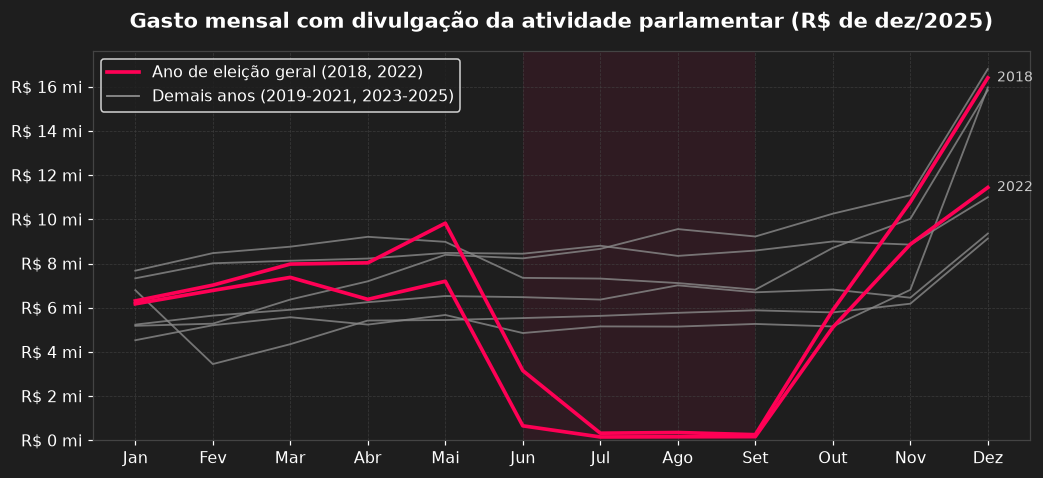

,tipo_de_ano,parcela_jul_set_da_divulgacao_anual
ano,,
2018,eleição geral,1.2%
2019,sem eleição,24.9%
2020,eleição municipal,20.9%
2021,sem eleição,25.5%
2022,eleição geral,0.8%
2023,sem eleição,25.8%
2024,eleição municipal,20.0%
2025,sem eleição,24.9%


In [11]:
DIVULGACAO = 'Divulgação da atividade parlamentar'
divulgacao = (ceap[ceap['categoria'] == DIVULGACAO]
              .assign(real=lambda d: d['valor_liquido'] * d['competencia'].map(ipca['fator_dez']))
              .groupby(['ano', 'mes'])['real'].sum().unstack())

fig, ax = plt.subplots(figsize=(11, 4.6))
for ano in divulgacao.index:
    eleicao = ano in (2018, 2022)
    ax.plot(range(12), divulgacao.loc[ano], color=ROSA if eleicao else CINZA,
            lw=2.4 if eleicao else 1.2, alpha=1 if eleicao else 0.8, zorder=3 if eleicao else 2)
    if eleicao:
        ax.annotate(str(ano), (11, divulgacao.loc[ano, 12]), xytext=(6, 0), textcoords='offset points',
                    color=TINTA_2, fontsize=9, va='center')
ax.plot([], [], color=ROSA, lw=2.4, label='Ano de eleição geral (2018, 2022)')
ax.plot([], [], color=CINZA, lw=1.2, label='Demais anos (2019-2021, 2023-2025)')
ax.axvspan(5, 8, color=ROSA, alpha=0.08, lw=0)
ax.set_xticks(range(12), MESES)
ax.yaxis.set_major_formatter(reais_mi)
ax.set_ylim(bottom=0)
ax.set_title('Gasto mensal com divulgação da atividade parlamentar (R$ de dez/2025)')
ax.legend(loc='upper left')
salvar(fig, '04_divulgacao')

participacao = divulgacao.loc[:, 7:9].sum(axis=1) / divulgacao.sum(axis=1)
tipo = pd.Series('sem eleição', index=participacao.index)
tipo[[2018, 2022]] = 'eleição geral'
tipo[[2020, 2024]] = 'eleição municipal'
display(pd.DataFrame({'tipo_de_ano': tipo, 'parcela_jul_set_da_divulgacao_anual': participacao})
        .style.format({'parcela_jul_set_da_divulgacao_anual': '{:.1%}'}))

**Leitura.** Nos anos de eleição geral, julho a setembro ficaram com 1,2% (2018) e 0,8% (2022) do gasto anual com divulgação, contra cerca de 25% nos anos sem eleição. Na prática, a divulgação paga pela cota vai a zero. Nos anos de eleição municipal, a parcela fica perto de 20%, uma queda pequena e compatível com a regra valer só para os deputados candidatos. O dinheiro que deixa de ser gasto reaparece de outubro a dezembro.

#### Verificação fora da amostra: 2026, outro ano de eleição geral

A eleição de 2026 é em outubro, e a mesma regra dos 120 dias vale a partir do início de junho. Esses dados não entraram em nenhuma estimativa acima. Se o padrão for real, junho e julho de 2026 devem ficar bem abaixo de fevereiro a maio, como em 2018 e 2022. Uso só junho e julho porque as notas podem ser apresentadas até 90 dias depois da despesa, e os meses seguintes ainda estão incompletos. O arquivo de 2026 muda todo dia; a célula mostra a data em que a Câmara gerou a versão usada.

In [12]:
garantir_arquivos({'Ano-2026.csv.zip': f'{BASE_CEAP}/Ano-2026.csv.zip'}, criar_sessao())
with zipfile.ZipFile(PASTA_DADOS / 'Ano-2026.csv.zip') as pacote:
    gerado_em = pd.Timestamp(*pacote.infolist()[0].date_time)
parcial_2026 = ler_ceap(2026)
parcial_2026 = parcial_2026[parcial_2026['id_deputado'].notna()].groupby('mes')['valor_liquido'].sum()
print(f'Arquivo de 2026 gerado pela Câmara em {gerado_em:%d/%m/%Y}')

razao = (por_mes[[6, 7]].mean(axis=1) / por_mes[[2, 3, 4, 5]].mean(axis=1)).rename('jun_jul_sobre_fev_mai').to_frame()
razao.loc[2026] = parcial_2026[[6, 7]].mean() / parcial_2026[[2, 3, 4, 5]].mean()
razao['tipo_de_ano'] = ['eleição geral' if a in (2018, 2022, 2026) else 'outro' for a in razao.index]
display(razao.style.format({'jun_jul_sobre_fev_mai': '{:.2f}'}))

Arquivo de 2026 gerado pela Câmara em 07/11/2026


,jun_jul_sobre_fev_mai,tipo_de_ano
competencia,,
2018,0.73,eleição geral
2019,1.02,outro
2020,0.87,outro
2021,1.08,outro
2022,0.73,eleição geral
2023,1.10,outro
2024,0.92,outro
2025,1.02,outro
2026,0.58,eleição geral


**Leitura.** Em 2026, junho e julho ficaram em 0,58 da média de fevereiro a maio, contra 0,73 em 2018 e 2022 e entre 0,87 e 1,10 nos outros anos. O padrão se repetiu num ano que não entrou em nenhuma estimativa. A queda maior pode ser em parte notas que ainda não foram lançadas, então o valor exato de 2026 não deve ser comparado diretamente.

### 4.6 Dezembro: o efeito "use ou perca" acontece?

O art. 13 do Ato da Mesa nº 43/2009 diz que o saldo da cota que não foi usado se acumula ao longo do ano, mas não passa para o ano seguinte. Isso cria um incentivo para gastar o que sobrou em dezembro. Se o mecanismo existe, **deputados que chegam a dezembro com mais saldo devem gastar mais em dezembro**.

O teste usa 2024 e 2025, anos sem troca de legislatura e já com os valores da cota de 2023. Entram os deputados em exercício em pelo menos 95% dos dias do ano, segundo o histórico oficial (Seção 4.6.1):

- teto do ano = 12 × cota mensal da UF (anexo do Ato da Mesa nº 43/2009, com a redação do Ato da Mesa nº 270/2023, em vigor desde 1º/2/2023);
- saldo disponível em dezembro = teto do ano − gasto de janeiro a novembro.

O teste é conservador. Quem gasta pouco o ano todo tende a gastar pouco também em dezembro, o que puxaria a correlação para o lado negativo. Se mesmo assim a correlação sair positiva, é um sinal mais forte de que o mecanismo existe.

#### 4.6.1 Quem estava no cargo: histórico oficial de exercício

Comparar gastos anuais exige saber quem ocupou o cargo o ano todo. Um suplente que ficou dois meses gasta pouco porque ficou pouco, não porque economizou. Na primeira versão desta revisão usei um atalho: considerar "ano completo" quem teve despesa em todos os meses. O atalho tinha um viés justamente no tema da análise, porque excluía deputados econômicos que passam meses sem lançar nada. Amom Mandel, destaque da v1, ficava de fora.

A fonte correta é o endpoint `/deputados/{id}/historico` da API, que registra posse, licença (por exemplo, para ser ministro), reassunção e renúncia, com data e hora. Aqui as funções da Seção 2 trabalham com dados reais:

- o histórico de cada deputado que aparece na cota de 2018 a 2025 é buscado em paralelo, com novas tentativas, e guardado em `Dados/brutos/historico_deputados.json`;
- quem falhar é tentado numa segunda rodada;
- se ainda faltar alguém, **o notebook não para nem esconde**: para essas pessoas, usa o critério de reserva (despesa em todos os meses do período) e avisa quantas foram.

In [13]:
API = 'https://dadosabertos.camara.leg.br/api/v2'
CACHE_HISTORICO = PASTA_DADOS / 'historico_deputados.json'


def obter_historicos(ids, rodadas=2):
    """Histórico de exercício de cada deputado, com cache local.

    Devolve (historicos, sem_historico): quem continuou falhando depois de todas as rodadas
    volta na segunda lista, para quem chamou decidir o que fazer.
    """
    try:
        cache = json.loads(CACHE_HISTORICO.read_text(encoding='utf-8'))
    except FileNotFoundError:
        cache = {}
    except json.JSONDecodeError:
        log.warning('cache do histórico corrompido; buscando tudo de novo')
        cache = {}
    faltando = sorted(set(ids) - set(cache))
    for rodada in range(1, rodadas + 1):
        if not faltando:
            break
        log.info('rodada %d: buscando o histórico de %d deputados na API', rodada, len(faltando))
        resultados, falhas = extrair_em_paralelo(faltando, lambda id_: f'{API}/deputados/{id_}/historico', None)
        cache.update(resultados)
        faltando = sorted(falhas)
    temporario = CACHE_HISTORICO.with_suffix('.tmp')
    temporario.write_text(json.dumps(cache), encoding='utf-8')
    temporario.replace(CACHE_HISTORICO)
    return cache, faltando


def dias_em_exercicio(eventos, inicio, fim):
    """Dias entre inicio e fim (inclusive) em que a situação do deputado era 'Exercício'."""
    mudancas = sorted((pd.Timestamp(e['dataHora']), e['situacao']) for e in eventos if e.get('situacao'))
    inicio, fim = pd.Timestamp(inicio), pd.Timestamp(fim) + pd.Timedelta(days=1)
    total = pd.Timedelta(0)
    for (desde, situacao), (ate, _) in zip(mudancas, mudancas[1:] + [(pd.Timestamp.max, None)]):
        if situacao == 'Exercício':
            total += max(min(ate, fim) - max(desde, inicio), pd.Timedelta(0))
    return total / pd.Timedelta(days=1)


historicos, sem_historico = obter_historicos(sorted(ceap['id_deputado'].unique()))
if sem_historico:
    log.warning('%d deputados sem histórico depois de todas as tentativas; para eles vale o critério de reserva '
                '(despesas em todos os meses do período)', len(sem_historico))
print(f'Histórico obtido para {len(historicos)} de {ceap["id_deputado"].nunique()} deputados')

# Dias em exercício de fevereiro a dezembro (janela comparável entre anos) e no ano inteiro.
exercicio_fev_dez = pd.DataFrame({ano: {id_: dias_em_exercicio(ev, f'{ano}-02-01', f'{ano}-12-31')
                                         for id_, ev in historicos.items()} for ano in ANOS})
exercicio_ano = pd.DataFrame({ano: {id_: dias_em_exercicio(ev, f'{ano}-01-01', f'{ano}-12-31')
                                     for id_, ev in historicos.items()} for ano in (2024, 2025)})


def em_exercicio(ano, tabela_dias, minimo, presentes, dias_no_periodo, meses_do_periodo):
    """Ids em exercício em pelo menos `minimo` dos dias do período.

    Para quem ficou sem histórico, cai no critério de reserva: despesas em todos os meses do período.
    """
    dias = tabela_dias[ano]
    ids = set(dias.index[dias >= minimo * dias_no_periodo])
    if sem_historico:
        meses = presentes.groupby('id_deputado')['mes'].nunique()
        ids |= {i for i in sem_historico if meses.get(i, 0) == meses_do_periodo}
    return ids


exemplos = {'220715': 'Amom Mandel', '204503': 'Alexandre Padilha', '204507': 'Carla Zambelli'}
display(pd.DataFrame({nome: exercicio_fev_dez.loc[id_, [2024, 2025]] for id_, nome in exemplos.items()
                      if id_ in exercicio_fev_dez.index}).T.rename(columns=lambda a: f'dias fev-dez {a}'))

Histórico obtido para 1179 de 1179 deputados


,dias fev-dez 2024,dias fev-dez 2025
Amom Mandel,335.00,334.00
Alexandre Padilha,0.00,2.51
Carla Zambelli,335.00,189.62


Os três exemplos mostram por que o histórico importa. Amom Mandel ficou no cargo o ano todo, embora tenha passado meses sem lançar despesas. Alexandre Padilha voltou à Câmara por poucos dias em 2025, entre ministérios. Carla Zambelli se licenciou em maio, voltou em outubro e renunciou em dezembro.

#### 4.6.2 O teste

,deputados,spearman_saldo_x_dezembro,ic_95,dezembro_acima_da_propria_media,indice_sazonal_dezembro
ano,,,,,
2024,463,0.41,0.31 a 0.50,58%,1.26
2025,477,0.21,0.11 a 0.30,30%,0.89



Dezembro menos a média de jan-nov, por categoria (R$ milhões, valores nominais):


ano,2018,2019,2020,2021,2022,2023,2024,2025
Divulgação da atividade parlamentar,+7.6,+2.7,+8.1,+2.8,+6.2,+8.1,+7.5,+2.7
Passagens aéreas,-0.0,-2.7,+1.8,+0.6,+0.4,-0.6,+0.2,-2.5
Consultorias e pesquisas,+0.9,+0.4,+1.9,-0.3,+0.8,-0.1,+0.0,+0.0
Locação de veículos,-0.4,-0.3,+0.1,-0.6,-0.1,-0.1,-0.5,-0.9
Escritório de apoio,-0.3,-0.2,+0.1,-0.4,-0.2,+0.1,-0.3,-0.6
Demais categorias,-0.4,-0.4,+0.6,-0.1,-0.6,-0.3,-0.6,-0.8
Total,+7.4,-0.5,+12.5,+2.0,+6.5,+7.0,+6.4,-2.0


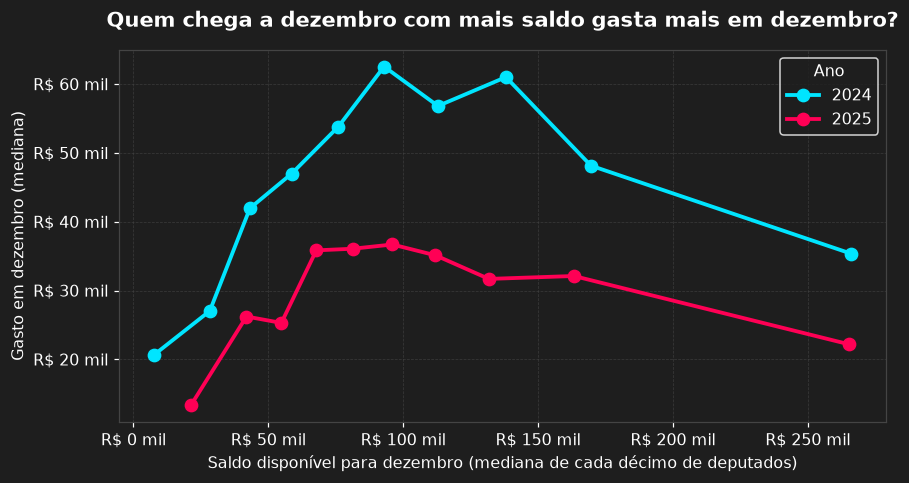

In [14]:
COTA_MENSAL = {  # R$ por mês; Anexo do Ato da Mesa nº 43/2009 (redação do Ato da Mesa nº 270/2023)
    'AC': 50426.26, 'AL': 46737.90, 'AM': 49363.92, 'AP': 49168.58, 'BA': 44804.65, 'CE': 48245.57,
    'DF': 36582.46, 'ES': 43217.71, 'GO': 41300.86, 'MA': 47945.49, 'MG': 41886.51, 'MS': 46336.64,
    'MT': 45221.83, 'PA': 48021.25, 'PB': 47826.36, 'PE': 47470.60, 'PI': 46765.57, 'PR': 44665.66,
    'RJ': 41553.77, 'RN': 48525.79, 'RO': 49466.29, 'RR': 51406.33, 'RS': 46669.70, 'SC': 45671.58,
    'SE': 45933.06, 'SP': 42837.33, 'TO': 45297.41,
}


def ic_bootstrap(estatistica, *colunas, n=N_BOOTSTRAP, nivel=0.95, semente=SEMENTE):
    """IC percentil por reamostragem das linhas (pareada quando há mais de uma coluna)."""
    gerador = np.random.default_rng(semente)
    arrays = [np.asarray(c, dtype=float) for c in colunas]
    tamanho = arrays[0].size
    valores = np.empty(n)
    for i in range(n):
        idx = gerador.integers(0, tamanho, tamanho)
        valores[i] = estatistica(*(a[idx] for a in arrays))
    return np.quantile(valores, [(1 - nivel) / 2, (1 + nivel) / 2])


spearman = lambda x, y: stats.spearmanr(x, y).statistic

linhas, bases_dezembro = [], {}
for ano in (2024, 2025):
    do_ano = ceap[ceap['ano'] == ano]
    dias_no_ano = 366 if ano % 4 == 0 else 365
    completos = do_ano[do_ano['id_deputado'].isin(em_exercicio(ano, exercicio_ano, 0.95, do_ano, dias_no_ano, 12))]
    tabela = completos.pivot_table(index='id_deputado', columns='mes', values='valor_liquido',
                                   aggfunc='sum', fill_value=0).reindex(columns=range(1, 13), fill_value=0)
    tabela['uf'] = completos.sort_values('mes').groupby('id_deputado')['uf'].last()
    tabela['saldo_dezembro'] = 12 * tabela['uf'].map(COTA_MENSAL) - tabela[list(range(1, 12))].sum(axis=1)
    tabela['gasto_dezembro'] = tabela[12]
    tabela['media_jan_nov'] = tabela[list(range(1, 12))].mean(axis=1)
    bases_dezembro[ano] = tabela
    rho = spearman(tabela['saldo_dezembro'], tabela['gasto_dezembro'])
    baixo, alto = ic_bootstrap(spearman, tabela['saldo_dezembro'], tabela['gasto_dezembro'])
    linhas.append({'ano': ano, 'deputados': len(tabela), 'spearman_saldo_x_dezembro': rho,
                   'ic_95': f'{baixo:.2f} a {alto:.2f}',
                   'dezembro_acima_da_propria_media': (tabela['gasto_dezembro'] > tabela['media_jan_nov']).mean(),
                   'indice_sazonal_dezembro': indice.loc[ano, 12]})
display(pd.DataFrame(linhas).set_index('ano').style.format(
    {'spearman_saldo_x_dezembro': '{:.2f}', 'dezembro_acima_da_propria_media': '{:.0%}', 'indice_sazonal_dezembro': '{:.2f}'}))

# De onde vem o "a mais" de dezembro: gasto de dezembro menos a média de jan-nov, por categoria (R$ mi).
por_categoria = ceap.pivot_table(index=['categoria', 'ano'], columns='mes', values='valor_liquido', aggfunc='sum', fill_value=0)
excesso_dezembro = ((por_categoria[12] - por_categoria[list(range(1, 12))].mean(axis=1)) / 1e6).unstack('ano').fillna(0)
principais = excesso_dezembro.abs().sum(axis=1).nlargest(5).index
excesso_dezembro = pd.concat([excesso_dezembro.loc[principais],
                              excesso_dezembro.drop(principais).sum().rename('Demais categorias').to_frame().T])
excesso_dezembro.loc['Total'] = excesso_dezembro.sum()
print('\nDezembro menos a média de jan-nov, por categoria (R$ milhões, valores nominais):')
display(excesso_dezembro.style.format('{:+.1f}'))

fig, ax = plt.subplots(figsize=(9, 4.4))
for ano, cor in ((2024, CIANO), (2025, ROSA)):
    tabela = bases_dezembro[ano]
    faixa = pd.qcut(tabela['saldo_dezembro'], 10, labels=False)
    pontos = tabela.groupby(faixa).agg(saldo=('saldo_dezembro', 'median'), dezembro=('gasto_dezembro', 'median'))
    ax.plot(pontos['saldo'], pontos['dezembro'], 'o-', color=cor, ms=8, label=str(ano))
ax.xaxis.set_major_formatter(reais_mil)
ax.yaxis.set_major_formatter(reais_mil)
ax.set_xlabel('Saldo disponível para dezembro (mediana de cada décimo de deputados)')
ax.set_ylabel('Gasto em dezembro (mediana)')
ax.set_title('Quem chega a dezembro com mais saldo gasta mais em dezembro?')
ax.legend(title='Ano')
salvar(fig, '05_use_ou_perca')

**Leitura.** Nos dois anos, quem chegou a dezembro com mais saldo gastou mais em dezembro: ρ = 0,41 em 2024 e 0,21 em 2025, com os dois intervalos acima de zero. A curva sobe até um saldo de algo entre R$ 70 mil e R$ 140 mil e depois desce, porque os deputados com saldo muito grande são os que gastam pouco o ano inteiro e continuam assim em dezembro. Isso é coerente com o efeito "use ou perca", com a ressalva de que correlação não prova o mecanismo.

A tabela por categoria mostra que **o "a mais" de dezembro é quase todo divulgação**, entre R$ 2,7 mi e R$ 8,1 mi por ano. Os maiores valores aparecem em anos em que algo impediu o gasto antes: 2018 e 2022, com a divulgação proibida de junho a setembro, e 2020, com a pandemia. Também aparecem em 2023 e 2024. Em 2025, o excesso de divulgação foi pequeno (+R$ 2,7 mi) e as passagens aéreas caíram R$ 2,5 mi, o que explica o dezembro abaixo da média. Os dados não dizem por quê.

## 5. Concentração: índice de Gini e curva de Lorenz

A **curva de Lorenz** ordena os deputados do menor para o maior valor e mostra, para cada fração da população (eixo x), que fração do total ela acumula (eixo y). Se todos tivessem o mesmo valor, a curva seria a diagonal. Quanto mais ela se afasta da diagonal, mais concentrado é o total.

O **índice de Gini** é o dobro da área entre a diagonal e a curva. Vai de 0, quando todos têm o mesmo, a 1, quando um só tem tudo. Com os valores ordenados $x_1 \le \dots \le x_n$:

$$G = \frac{\sum_{i=1}^{n} (2i - n - 1)\,x_i}{n \sum_{i=1}^{n} x_i}$$

O intervalo de confiança vem de bootstrap, reamostrando deputados 2.000 vezes.

**Quem entra:** deputados em exercício em pelo menos 90% dos dias de fevereiro a dezembro, segundo o histórico oficial (Seção 4.6.1). Janeiro fica de fora porque, em 2019 e 2023, ele ainda é da legislatura anterior (a posse é em 1º de fevereiro) e porque é mês de recesso. Sem esse filtro, um suplente que ficou dois meses no cargo apareceria como "gastador econômico", e o Gini mediria rotatividade, não comportamento. O teto usado no "% do teto" é proporcional aos dias em exercício, como manda o art. 11 do Ato da Mesa: 11 × cota mensal da UF × (dias em exercício ÷ dias de fevereiro a dezembro).

In [15]:
def gini(valores):
    x = np.sort(np.asarray(valores, dtype=float))
    if (x < 0).any():
        raise ValueError('o índice de Gini exige valores não negativos')
    n = x.size
    return np.sum((2 * np.arange(1, n + 1) - n - 1) * x) / (n * x.sum())


def curva_lorenz(valores):
    x = np.sort(np.asarray(valores, dtype=float))
    return np.linspace(0, 1, x.size + 1), np.concatenate([[0], np.cumsum(x) / x.sum()])


def parcela_do_topo(valores, fracao):
    x = np.sort(np.asarray(valores, dtype=float))[::-1]
    return x[: max(1, round(fracao * x.size))].sum() / x.sum()


CADASTRO = ceap.sort_values(['ano', 'mes']).groupby('id_deputado')[['nome', 'uf', 'partido']].last()


def gasto_fev_dez(ano, minimo=0.9):
    """Gasto de fevereiro a dezembro dos deputados em exercício em pelo menos 90% desses dias."""
    periodo = ceap[(ceap['ano'] == ano) & (ceap['mes'] >= 2)]
    dias_no_periodo = (pd.Timestamp(ano, 12, 31) - pd.Timestamp(ano, 2, 1)).days + 1
    ids = sorted(em_exercicio(ano, exercicio_fev_dez, minimo, periodo, dias_no_periodo, 11))
    # Agrupa só pelo id: quem troca de partido no meio do ano continua sendo um deputado só.
    cadastro = periodo.sort_values('mes').groupby('id_deputado')[['nome', 'uf', 'partido']].last()
    tabela = cadastro.combine_first(CADASTRO).reindex(ids)
    tabela['gasto'] = periodo.groupby('id_deputado')['valor_liquido'].sum().reindex(ids).fillna(0)
    tabela['fracao_exercicio'] = (exercicio_fev_dez[ano].reindex(ids) / dias_no_periodo).fillna(1).clip(upper=1)
    tabela.index.name = 'id_deputado'
    return tabela.reset_index()


base = gasto_fev_dez(ANO_FOCO)
base['teto'] = 11 * base['uf'].map(COTA_MENSAL) * base['fracao_exercicio']
base['pct_teto'] = base['gasto'] / base['teto']
print(f'{len(base)} deputados em exercício em pelo menos 90% dos dias de fev a dez de {ANO_FOCO}')
print(f'{(base["gasto"] <= 0).sum()} deles sem nenhum gasto líquido positivo no período')
print(f'Uso do teto: mediana {base["pct_teto"].median():.0%}; '
      f'{(base["pct_teto"] >= 0.9).mean():.0%} usaram 90% ou mais; {(base["pct_teto"] < 0.5).mean():.0%} usaram menos da metade')

482 deputados em exercício em pelo menos 90% dos dias de fev a dez de 2025
0 deles sem nenhum gasto líquido positivo no período
Uso do teto: mediana 91%; 56% usaram 90% ou mais; 4% usaram menos da metade


**Leitura.** O deputado mediano usou 91% do teto, e mais da metade usou 90% ou mais. Com a maioria encostada no limite, o gasto tem pouco espaço para variar. É isso que a Seção 5.2 mede.

### 5.1 Produção legislativa por deputado, sem contar coautoria em dobro

O arquivo `proposicoesAutores` lista todos os autores de cada proposição. São três maneiras de contar:

- **autorias**: quantas proposições o deputado assinou. Foi o que a v1 contou, porque a API devolve a proposição para cada coautor. Uma PEC com 171 assinaturas vira 171 "projetos".
- **primeiro autor**: só quando o deputado é o primeiro signatário.
- **projetos (autoria fracionada)**: cada proposição vale 1, dividido igualmente entre todos os seus autores. A soma de todos os autores dá exatamente o número de proposições. **É a medida principal daqui em diante.**

Entram PL, PLP, PEC e PDL apresentados em 2025.

In [16]:
autores = pd.read_csv(PASTA_DADOS / f'proposicoesAutores-{ANO_FOCO}.csv', sep=';', encoding='utf-8-sig', dtype=str,
                      usecols=['idProposicao', 'uriAutor', 'idDeputadoAutor', 'tipoAutor', 'ordemAssinatura'])
proposicoes = pd.read_csv(PASTA_DADOS / f'proposicoes-{ANO_FOCO}.csv', sep=';', encoding='utf-8-sig', dtype=str,
                          usecols=['id', 'siglaTipo', 'ano', 'dataApresentacao'])
proposicoes = proposicoes[proposicoes['siglaTipo'].isin(TIPOS_PROJETO)
                          & (proposicoes['ano'] == str(ANO_FOCO))
                          & proposicoes['dataApresentacao'].str.startswith(str(ANO_FOCO))]

autoria = (autores.drop_duplicates(['idProposicao', 'uriAutor'])
           .merge(proposicoes[['id', 'siglaTipo']], left_on='idProposicao', right_on='id'))
autoria['n_autores'] = autoria.groupby('idProposicao')['uriAutor'].transform('size')
autoria['credito'] = 1 / autoria['n_autores']
de_deputados = autoria[autoria['tipoAutor'] == 'Deputado(a)']

contagem = pd.DataFrame({
    'proposicoes': autoria.groupby('siglaTipo')['idProposicao'].nunique(),
    'mediana_de_autores': autoria.drop_duplicates('idProposicao').groupby('siglaTipo')['n_autores'].median(),
    'autorias_de_deputados': de_deputados.groupby('siglaTipo').size(),
    'creditos_de_deputados': de_deputados.groupby('siglaTipo')['credito'].sum(),
})
contagem.loc['Total'] = contagem.sum()
contagem.loc['Total', 'mediana_de_autores'] = np.nan
display(contagem)
assert abs(autoria['credito'].sum() - autoria['idProposicao'].nunique()) < 1e-6
print(f'Contando como a v1, os deputados teriam {len(de_deputados):,} "projetos" '
      f'para {de_deputados["idProposicao"].nunique():,} proposições distintas '
      f'({len(de_deputados) / de_deputados["idProposicao"].nunique() - 1:.0%} a mais).')

producao = de_deputados.groupby('idDeputadoAutor').agg(
    autorias=('idProposicao', 'nunique'),
    primeiro_autor=('ordemAssinatura', lambda s: (s == '1').sum()),
    projetos=('credito', 'sum'),
)
base = base.merge(producao, left_on='id_deputado', right_index=True, how='left')
base[['autorias', 'primeiro_autor', 'projetos']] = base[['autorias', 'primeiro_autor', 'projetos']].fillna(0)
print(f'Deputados da base sem nenhum PL, PLP, PEC ou PDL em {ANO_FOCO}: {(base["projetos"] == 0).sum()} de {len(base)}')

,proposicoes,mediana_de_autores,autorias_de_deputados,creditos_de_deputados
siglaTipo,,,,
PDL,1147,1.00,1183,409.00
PEC,22,172.00,3351,19.00
PL,6495,1.00,7829,"6,426.00"
PLP,232,1.00,342,228.00
Total,7896,NaN,12705,"7,082.00"


Contando como a v1, os deputados teriam 12,705 "projetos" para 7,082 proposições distintas (79% a mais).
Deputados da base sem nenhum PL, PLP, PEC ou PDL em 2025: 1 de 482


**Leitura.** Contando como a v1, os deputados teriam 12.705 "projetos" para 7.082 proposições distintas, 79% a mais. Quase toda a diferença vem das PECs: as 22 PECs de 2025 tiveram mediana de 172 autores e viraram 3.351 autorias. Os PDLs também pesam, com mediana de 1 autor mas alguns com mais de 100.

### 5.2 Gini e Lorenz: gasto × produção

,gini,ic_95,parcela_dos_10pct_do_topo,parcela_dos_50pct_de_baixo
medida,,,,
Gasto na cota (R$),0.09,0.08 a 0.10,12%,44%
% do teto usado,0.08,0.07 a 0.09,12%,45%
Projetos (autoria fracionada),0.63,0.54 a 0.69,51%,11%
Primeiro autor,0.63,0.55 a 0.70,51%,11%
Autorias (contagem da v1),0.46,0.40 a 0.52,36%,21%


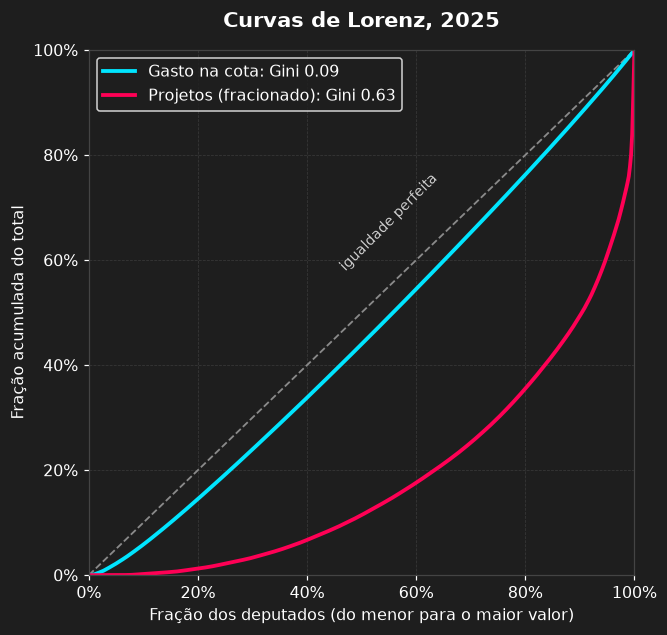

In [17]:
medidas = {
    'Gasto na cota (R$)': base['gasto'],
    '% do teto usado': base['pct_teto'],
    'Projetos (autoria fracionada)': base['projetos'],
    'Primeiro autor': base['primeiro_autor'],
    'Autorias (contagem da v1)': base['autorias'],
}
resumo_gini = pd.DataFrame([
    {'medida': nome, 'gini': gini(v), 'ic_95': '{:.2f} a {:.2f}'.format(*ic_bootstrap(gini, v)),
     'parcela_dos_10pct_do_topo': parcela_do_topo(v, 0.10), 'parcela_dos_50pct_de_baixo': 1 - parcela_do_topo(v, 0.50)}
    for nome, v in medidas.items()
]).set_index('medida')
display(resumo_gini.style.format({'gini': '{:.2f}', 'parcela_dos_10pct_do_topo': '{:.0%}', 'parcela_dos_50pct_de_baixo': '{:.0%}'}))

fig, ax = plt.subplots(figsize=(6.4, 6.2))
ax.plot([0, 1], [0, 1], color=CINZA, ls='--', lw=1.2)
ax.annotate('igualdade perfeita', (0.55, 0.58), rotation=45, color=TINTA_2, fontsize=9, ha='center')
for coluna, nome, cor in (('gasto', 'Gasto na cota', CIANO), ('projetos', 'Projetos (fracionado)', ROSA)):
    px, py = curva_lorenz(base[coluna])
    ax.plot(px, py, color=cor, label=f'{nome}: Gini {gini(base[coluna]):.2f}')
ax.set_xlabel('Fração dos deputados (do menor para o maior valor)')
ax.set_ylabel('Fração acumulada do total')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title(f'Curvas de Lorenz, {ANO_FOCO}')
ax.legend(loc='upper left')
salvar(fig, '06_lorenz')

**Leitura.** O gasto é quase uniforme: Gini de 0,09 (IC 0,08 a 0,10), e os 10% que mais gastam ficam com 12% do total, quase a parcela que teriam se todos gastassem igual. A produção é muito concentrada: Gini de 0,63 (IC 0,54 a 0,69), e os 10% mais produtivos respondem por 51% dos projetos. A contagem da v1 dá um Gini menor (0,46) porque espalha as PECs, assinadas por quase todo mundo, entre centenas de deputados.

### 5.3 Por que o gasto é tão pouco concentrado? Decomposição de Theil por estado

O Gini não se decompõe de forma limpa entre grupos. O índice de Theil se decompõe: $T = T_{\text{entre}} + T_{\text{dentro}}$. A parte "entre estados" mede quanto da desigualdade de gasto se explica só pelo estado do deputado. A cota de Roraima é 41% maior que a do Distrito Federal, então parte da diferença já vem das regras.

In [18]:
def theil(valores):
    x = np.asarray(valores, dtype=float)
    r = x / x.mean()
    return np.mean(np.where(r > 0, r * np.log(np.where(r > 0, r, 1)), 0.0))   # r·ln r → 0 quando r → 0


def decompor_theil(valores, grupos):
    tabela = pd.DataFrame({'x': np.asarray(valores, dtype=float), 'g': np.asarray(grupos)})
    media, n = tabela['x'].mean(), len(tabela)
    entre = dentro = 0.0
    for _, grupo in tabela.groupby('g')['x']:
        peso = len(grupo) / n * grupo.mean() / media     # parcela do total que está no grupo
        entre += peso * np.log(grupo.mean() / media)
        dentro += peso * theil(grupo)
    return entre, dentro


entre, dentro = decompor_theil(base['gasto'], base['uf'])
print(f'Theil do gasto em {ANO_FOCO}: {theil(base["gasto"]):.4f}')
print(f'  entre estados: {entre:.4f} ({entre / (entre + dentro):.0%})')
print(f'  dentro dos estados: {dentro:.4f} ({dentro / (entre + dentro):.0%})')

Theil do gasto em 2025: 0.0196
  entre estados: 0.0034 (17%)
  dentro dos estados: 0.0163 (83%)


**Leitura.** Só 17% da desigualdade de gasto, que já é pequena, se explica pelo estado. Os outros 83% são diferenças entre deputados do mesmo estado.

### 5.4 O Gini do gasto mudou ao longo dos anos?

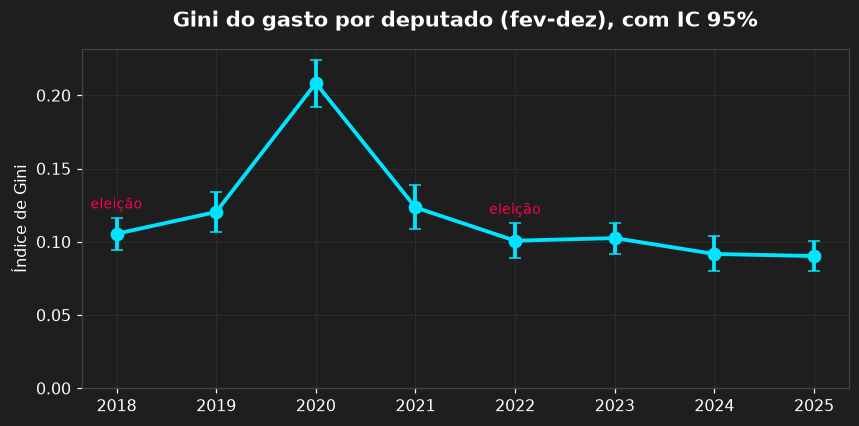

,deputados,gini,ic_baixo,ic_alto
ano,,,,
2018,469,0.105,0.095,0.117
2019,499,0.120,0.107,0.134
2020,483,0.208,0.192,0.224
2021,487,0.123,0.109,0.139
2022,471,0.101,0.089,0.113
2023,487,0.103,0.091,0.113
2024,467,0.092,0.080,0.104
2025,482,0.090,0.080,0.101


In [19]:
gini_anos = []
for ano in ANOS:
    gastos = gasto_fev_dez(ano)['gasto']
    baixo, alto = ic_bootstrap(gini, gastos)
    gini_anos.append({'ano': ano, 'deputados': len(gastos), 'gini': gini(gastos), 'ic_baixo': baixo, 'ic_alto': alto})
gini_anos = pd.DataFrame(gini_anos).set_index('ano')

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(gini_anos.index, gini_anos['gini'],
            yerr=[gini_anos['gini'] - gini_anos['ic_baixo'], gini_anos['ic_alto'] - gini_anos['gini']],
            fmt='o-', color=CIANO, ms=8, capsize=4)
for ano in (2018, 2022):
    ax.annotate('eleição', (ano, gini_anos.loc[ano, 'ic_alto']), xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=9, color=ROSA)
ax.set_xticks(ANOS)
ax.set_ylim(bottom=0)
ax.set_title('Gini do gasto por deputado (fev-dez), com IC 95%')
ax.set_ylabel('Índice de Gini')
salvar(fig, '07_gini_anos')
display(gini_anos.style.format({'gini': '{:.3f}', 'ic_baixo': '{:.3f}', 'ic_alto': '{:.3f}'}))

**Leitura.** Entre 2018 e 2025, o Gini do gasto ficou entre 0,09 e 0,12, com uma exceção: 0,21 em 2020. Na pandemia, alguns deputados pararam de viajar e outros não. Desde 2021 o índice cai devagar (de 0,12 para 0,09), ou seja, os deputados gastam de forma cada vez mais parecida, perto do teto.

### 5.5 Onde o dinheiro se concentra: fornecedores por categoria

Para a fiscalização, a concentração que interessa é a de **fornecedores**: se poucos CNPJs recebem a maior parte do dinheiro de uma categoria, auditar esses poucos cobre muito do valor. A tabela usa todos os deputados de 2025 e soma o valor líquido por CPF/CNPJ de fornecedor.

In [20]:
do_ano = ceap[ceap['ano'] == ANO_FOCO]
linhas = []
for categoria, grupo in do_ano.groupby('categoria'):
    por_fornecedor = grupo.groupby('fornecedor_doc')['valor_liquido'].sum()
    por_fornecedor = por_fornecedor[por_fornecedor > 0]
    if por_fornecedor.sum() < 1e6:
        continue
    linhas.append({'categoria': categoria, 'total_R_mi': por_fornecedor.sum() / 1e6,
                   'fornecedores': len(por_fornecedor), 'gini': gini(por_fornecedor),
                   'parcela_do_1pct_do_topo': parcela_do_topo(por_fornecedor, 0.01),
                   'parcela_dos_10_maiores': por_fornecedor.nlargest(10).sum() / por_fornecedor.sum()})
fornecedores = pd.DataFrame(linhas).set_index('categoria').sort_values('total_R_mi', ascending=False)
display(fornecedores.style.format({'total_R_mi': '{:.1f}', 'fornecedores': '{:,.0f}', 'gini': '{:.2f}',
                                   'parcela_do_1pct_do_topo': '{:.0%}', 'parcela_dos_10_maiores': '{:.0%}'}))

,total_R_mi,fornecedores,gini,parcela_do_1pct_do_topo,parcela_dos_10_maiores
categoria,,,,,
Divulgação da atividade parlamentar,101.9,"3,139",0.72,15%,8%
Locação de veículos,41.8,444,0.65,18%,29%
Escritório de apoio,33.4,"1,429",0.69,11%,9%
Passagens aéreas,29.0,26,0.91,59%,100%
Combustíveis,22.4,"11,600",0.78,36%,8%
Hospedagem,3.9,"2,426",0.61,17%,11%
Telefonia,2.9,95,0.91,46%,89%
Locação ou fretamento de aeronaves,2.1,21,0.57,17%,90%
Segurança,1.3,52,0.68,16%,72%


**Leitura.** Divulgação, a maior categoria (R$ 101,9 mi), é a mais pulverizada: 3.139 fornecedores, e os 10 maiores somam só 8%. Locação de veículos é bem mais concentrada (os 10 maiores ficam com 29% de R$ 41,8 mi), e combustíveis também, no topo (1% dos postos recebe 36%). Passagens e telefonia são concentradas por natureza, porque há poucas empresas. A v1 sugeria concentrar a fiscalização nas maiores categorias. A conclusão precisa de ajuste: a maior categoria é justamente a que tem mais fornecedores para auditar.

## 6. Gasto × produção legislativa

### 6.1 Ranking por partido, com e sem o tamanho da bancada

A v1 somava os projetos por partido e o PL liderava com 27% do total. Ela mesma reconhecia que isso refletia o tamanho da bancada, mas não corrigia. Aqui a medida é a média de projetos por deputado de cada partido, com intervalo de confiança por bootstrap, para partidos com pelo menos 10 deputados na base.

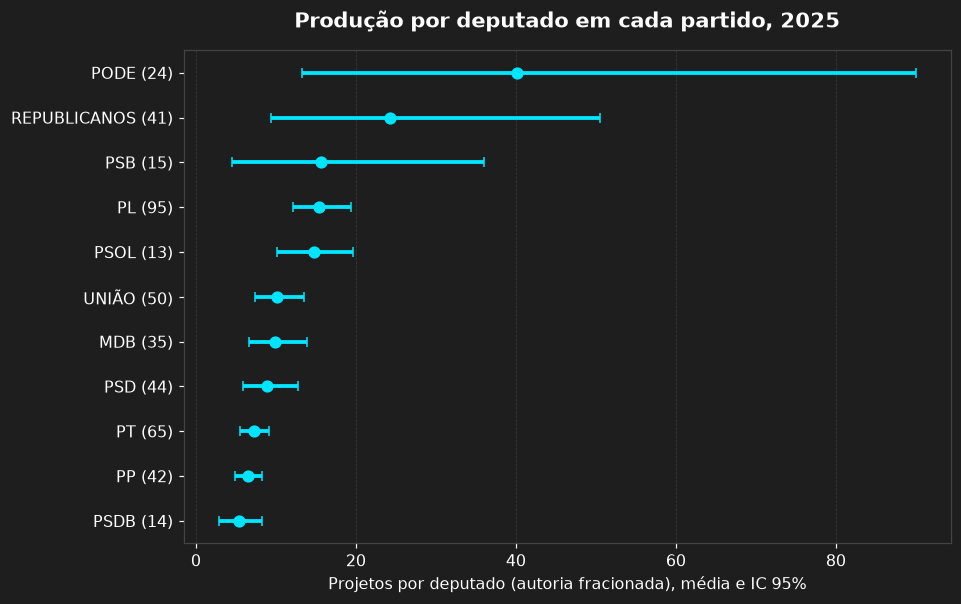

,deputados,autorias_v1,projetos,media_por_deputado,mediana_por_deputado,ic_baixo,ic_alto
partido,,,,,,,
PODE,24,"1,205",962.1,40.1,15.1,13.2,90.0
REPUBLICANOS,41,"1,393",994.9,24.3,9.2,9.4,50.5
PSB,15,348,235.2,15.7,7.3,4.6,36.1
PL,95,"3,187","1,463.1",15.4,10.5,12.2,19.4
PSOL,13,394,191.5,14.7,14.5,10.2,19.7
UNIÃO,50,962,507.6,10.2,8.1,7.3,13.5
MDB,35,618,344.1,9.8,6.0,6.6,13.9
PSD,44,718,390.4,8.9,6.1,5.9,12.7
PT,65,"1,140",468.4,7.2,5.2,5.5,9.1


In [21]:
partidos = base.groupby('partido').agg(deputados=('id_deputado', 'size'), autorias_v1=('autorias', 'sum'),
                                       projetos=('projetos', 'sum'), media_por_deputado=('projetos', 'mean'),
                                       mediana_por_deputado=('projetos', 'median'))
partidos = partidos[partidos['deputados'] >= 10].sort_values('media_por_deputado')
intervalos = np.array([ic_bootstrap(np.mean, base.loc[base['partido'] == p, 'projetos']) for p in partidos.index])
partidos['ic_baixo'], partidos['ic_alto'] = intervalos[:, 0], intervalos[:, 1]

fig, ax = plt.subplots(figsize=(9, 0.42 * len(partidos) + 1.2))
posicoes = np.arange(len(partidos))
ax.errorbar(partidos['media_por_deputado'], posicoes,
            xerr=[partidos['media_por_deputado'] - partidos['ic_baixo'], partidos['ic_alto'] - partidos['media_por_deputado']],
            fmt='o', color=CIANO, ms=7, capsize=3)
ax.set_yticks(posicoes, [f'{p} ({n})' for p, n in zip(partidos.index, partidos['deputados'])])
ax.set_xlabel('Projetos por deputado (autoria fracionada), média e IC 95%')
ax.set_title(f'Produção por deputado em cada partido, {ANO_FOCO}')
ax.grid(axis='y', visible=False)
salvar(fig, '08_partidos')
display(partidos.sort_values('media_por_deputado', ascending=False)
        .style.format({'autorias_v1': '{:,.0f}', 'projetos': '{:,.1f}', 'media_por_deputado': '{:.1f}',
                       'mediana_por_deputado': '{:.1f}', 'ic_baixo': '{:.1f}', 'ic_alto': '{:.1f}'}))

**Leitura.** Por deputado, os intervalos se sobrepõem bastante. PODE e REPUBLICANOS têm média alta puxada por uma pessoa cada: Duda Ramos (PODE-RR) e Amom Mandel (REPUBLICANOS-AM), com mais de 500 projetos cada. Isso aparece na distância entre média e mediana e nos intervalos largos. O PL, que liderava a soma da v1, tem 15,4 projetos por deputado (IC 12,2 a 19,4), acima de PT, PP e PSDB, mas no mesmo patamar de PSOL e PSB.

### 6.2 Correlação entre gasto e produção

A v1 olhou o gráfico de dispersão e concluiu que "o gasto não se correlaciona com a produtividade", sem medir. Aqui a correlação é a de **Spearman**, que usa a ordem e não o valor. É a escolha adequada para dados assimétricos e com valores extremos (três deputados somam mais de mil projetos). O resultado vem com intervalo de confiança por bootstrap e p-valor por permutação: embaralho a produção 10.000 vezes e vejo com que frequência sai uma correlação tão forte quanto a observada.

,x,y,spearman,ic_95,p_permutacao
0,gasto,projetos,-0.04,-0.13 a 0.05,0.3845
1,pct_teto,projetos,-0.01,-0.10 a 0.08,0.8217
2,gasto,primeiro_autor,-0.05,-0.14 a 0.04,0.2890
3,gasto,autorias,-0.05,-0.14 a 0.04,0.2957


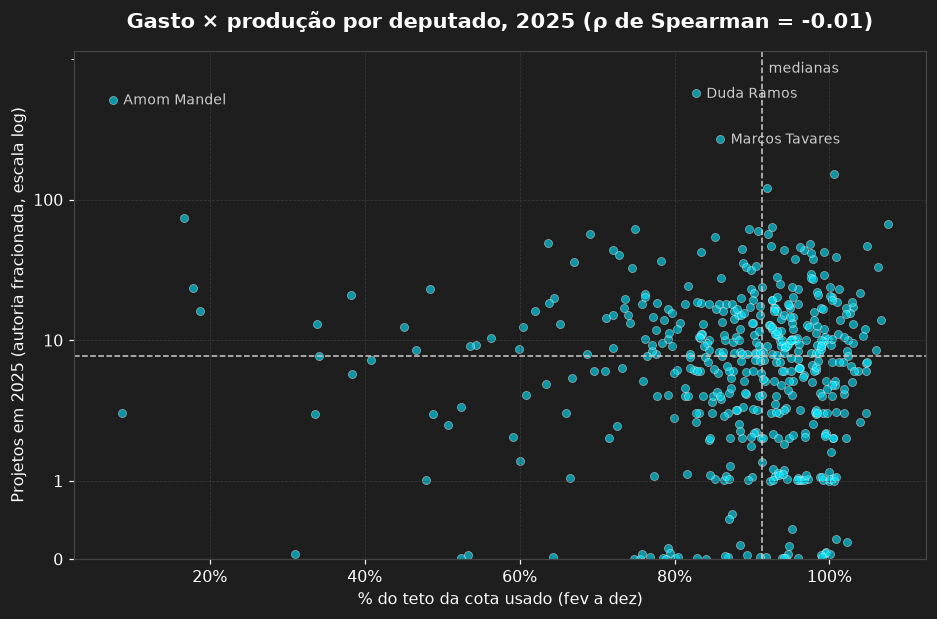

In [22]:
def p_permutacao_spearman(x, y, n=10_000, semente=SEMENTE):
    gerador = np.random.default_rng(semente)
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    observado = np.corrcoef(rx, ry)[0, 1]
    nulos = np.array([np.corrcoef(rx, gerador.permutation(ry))[0, 1] for _ in range(n)])
    return (np.sum(np.abs(nulos) >= abs(observado)) + 1) / (n + 1)


pares = [('gasto', 'projetos'), ('pct_teto', 'projetos'), ('gasto', 'primeiro_autor'), ('gasto', 'autorias')]
correlacoes = pd.DataFrame([
    {'x': x, 'y': y, 'spearman': spearman(base[x], base[y]),
     'ic_95': '{:.2f} a {:.2f}'.format(*ic_bootstrap(spearman, base[x], base[y])),
     'p_permutacao': p_permutacao_spearman(base[x], base[y])}
    for x, y in pares
])
display(correlacoes.style.format({'spearman': '{:.2f}', 'p_permutacao': '{:.4f}'}))

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(base['pct_teto'], base['projetos'], s=28, color=CIANO, alpha=0.6, edgecolor='white', linewidth=0.4)
ax.axvline(base['pct_teto'].median(), color=TINTA_2, ls='--', lw=1)
ax.axhline(base['projetos'].median(), color=TINTA_2, ls='--', lw=1)
ax.set_yscale('symlog', linthresh=1, linscale=0.5)
ax.set_ylim(0, base['projetos'].max() * 2)
ax.set_yticks([0, 1, 10, 100, 1000][: 2 + int(np.log10(base['projetos'].max()))])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
for _, linha in base.nlargest(3, 'projetos').iterrows():
    ax.annotate(linha['nome'], (linha['pct_teto'], linha['projetos']), xytext=(7, -3), textcoords='offset points',
                fontsize=9, color=TINTA_2)
ax.annotate('medianas', (base['pct_teto'].median(), base['projetos'].max() * 1.4), xytext=(4, 0),
            textcoords='offset points', fontsize=9, color=TINTA_2)
ax.set_xlabel('% do teto da cota usado (fev a dez)')
ax.set_ylabel('Projetos em 2025 (autoria fracionada, escala log)')
ax.set_title(f'Gasto × produção por deputado, {ANO_FOCO} (ρ de Spearman = {spearman(base["pct_teto"], base["projetos"]):.2f})')
salvar(fig, '09_gasto_x_producao')

**Leitura.** Não há associação entre gasto e produção: ρ = −0,04 (IC −0,13 a 0,05; p = 0,38). Com o % do teto, que desconta a diferença entre estados, ρ = −0,01. O intervalo permite descartar correlações moderadas: se houver alguma, ela é menor que 0,13 em módulo. A v1 tinha chegado a essa conclusão só olhando o gráfico, e agora ela tem medida e margem de erro. O gráfico também mostra que os três deputados mais produtivos estão em pontos muito diferentes de gasto (Amom Mandel usou 7% do teto).

### 6.3 Quadrantes: média × mediana

A v1 dividiu os deputados pela média de gasto e pela média de projetos. Com distribuições assimétricas, a média de projetos é puxada por poucos deputados muito produtivos e fica acima do que é típico. A maior parte da Câmara cai "abaixo da média", e o quadrante "ineficiência crítica" incha. A mediana divide a Câmara ao meio por construção, o que deixa os quadrantes comparáveis.

In [23]:
def quadrantes(tabela, x, y, corte):
    alto_x, alto_y = tabela[x] > corte(tabela[x]), tabela[y] > corte(tabela[y])
    return pd.Series({
        'gasto baixo, produção alta': (~alto_x & alto_y).sum(),
        'gasto alto, produção alta': (alto_x & alto_y).sum(),
        'gasto baixo, produção baixa': (~alto_x & ~alto_y).sum(),
        'gasto alto, produção baixa ("ineficiência crítica" na v1)': (alto_x & ~alto_y).sum(),
    })


comparacao = pd.DataFrame({
    'média, autorias (como na v1)': quadrantes(base, 'gasto', 'autorias', np.mean),
    'média, projetos fracionados': quadrantes(base, 'gasto', 'projetos', np.mean),
    'mediana, projetos fracionados': quadrantes(base, 'gasto', 'projetos', np.median),
})
display(comparacao)
print(f'Projetos por deputado: média {base["projetos"].mean():.1f}, mediana {base["projetos"].median():.1f}. '
      f'{(base["projetos"] < base["projetos"].mean()).mean():.0%} dos deputados ficam abaixo da média.')

,"média, autorias (como na v1)","média, projetos fracionados","mediana, projetos fracionados"
"gasto baixo, produção alta",63,55,127
"gasto alto, produção alta",78,70,114
"gasto baixo, produção baixa",126,134,114
"gasto alto, produção baixa (""ineficiência crítica"" na v1)",215,223,127


Projetos por deputado: média 14.0, mediana 7.8. 74% dos deputados ficam abaixo da média.


**Leitura.** Pela média, como na v1, 215 dos 482 deputados (45%) caem em "gasto alto, produção baixa" (223 com a contagem fracionada), porque cerca de três quartos dos deputados produzem abaixo da média. Pela mediana, são 127 (26%), muito perto dos 25% esperados se gasto e produção fossem independentes. Isso bate com a correlação nula da Seção 6.2. O quadrante "ineficiência crítica" da v1 era em boa parte um efeito da média.

### 6.4 Por que "custo por projeto" engana

A métrica central da v1 era `Custo_por_Projeto = gasto / projetos`. A Seção 5 mostrou que o gasto varia pouco (Gini baixo, e a maioria encosta no teto) e que a produção varia muito (Gini alto). A consequência é que a razão mede quase só o denominador. No log, a variância se decompõe exatamente:

$$\operatorname{Var}(\log c) = \operatorname{Var}(\log g) + \operatorname{Var}(\log p) - 2\operatorname{Cov}(\log g, \log p)$$

In [24]:
com_projeto = base[base['projetos'] > 0].copy()
com_projeto['custo_por_projeto'] = com_projeto['gasto'] / com_projeto['projetos']
log_g, log_p = np.log(com_projeto['gasto']), np.log(com_projeto['projetos'])
var_c = np.log(com_projeto['custo_por_projeto']).var()
partes = pd.Series({'Var(log gasto)': log_g.var(), 'Var(log projetos)': log_p.var(),
                    '-2 Cov(log gasto, log projetos)': -2 * np.cov(log_g, log_p)[0, 1]})
display((partes / var_c).rename('parcela da variância do log(custo por projeto)').to_frame()
        .style.format('{:.1%}'))
print(f'Spearman(custo por projeto, projetos) = {spearman(com_projeto["custo_por_projeto"], com_projeto["projetos"]):.2f}')
print(f'Spearman(custo por projeto, gasto)    = {spearman(com_projeto["custo_por_projeto"], com_projeto["gasto"]):.2f}')
q1, q2, q3 = com_projeto['custo_por_projeto'].quantile([0.25, 0.5, 0.75])
print(f'Custo por projeto: mediana R$ {q2:,.0f} (intervalo interquartil R$ {q1:,.0f} a R$ {q3:,.0f}); '
      f'média R$ {com_projeto["custo_por_projeto"].mean():,.0f}')

,parcela da variância do log(custo por projeto)
Var(log gasto),2.3%
Var(log projetos),96.0%
"-2 Cov(log gasto, log projetos)",1.6%


Spearman(custo por projeto, projetos) = -0.98
Spearman(custo por projeto, gasto)    = 0.18
Custo por projeto: mediana R$ 55,807 (intervalo interquartil R$ 28,261 a R$ 147,306); média R$ 1,535,019


**Leitura.** 96% da variância do log do custo por projeto vem do número de projetos, e só 2% do gasto. A correlação entre custo por projeto e número de projetos é −0,98. A média (R$ 1,5 milhão) é 27 vezes a mediana (R$ 55,8 mil), puxada por deputados com uma fração pequena de um único projeto. A métrica não diz nada sobre como o dinheiro foi usado. Ela só repete, invertido, quantos projetos cada deputado assinou.

## 7. Conclusões revisadas

Números desta execução (dados baixados em novembro de 2026).

1. **A sazonalidade existe, mas não é a que a v1 descreveu.** Com 8 anos, o padrão que se repete é janeiro cerca de 19% abaixo do mês médio, e novembro e dezembro de 11% a 14% acima. Dezembro ficou acima da média em 6 de 8 anos, e 2025, o ano da v1, foi uma das exceções.
2. **O maior efeito do calendário é eleitoral, e é forte.** De junho a setembro de anos de eleição geral, o gasto cai 41% (IC 95%: 34% a 48%), porque a divulgação paga pela cota vai a zero, como manda a regra dos 120 dias. Os dados parciais de 2026 repetem o padrão fora da amostra.
3. **Dezembro tem um componente "use ou perca".** Quem chega a dezembro com mais saldo gasta mais em dezembro (ρ = 0,41 em 2024 e 0,21 em 2025), e o excesso é quase todo divulgação.
4. **O gasto é quase igual entre deputados, e a produção não.** O Gini do gasto é 0,09, porque a maioria encosta no teto. O Gini da produção é 0,63, e 10% dos deputados respondem por metade dos projetos.
5. **Gasto e produção não têm relação mensurável.** ρ = −0,04, com IC de −0,13 a 0,05. Os quadrantes pela média da v1 inflavam a "ineficiência crítica" (215 deputados contra 127 pela mediana).
6. **"Custo por projeto" não mede eficiência.** 96% da variação dele vem do número de projetos. Ele é o inverso da produção, não uma medida de como o dinheiro é usado.
7. **Para a fiscalização, a maior categoria é a mais pulverizada.** Divulgação tem R$ 102 mi espalhados por 3.139 fornecedores. Locação de veículos e combustíveis são mais concentradas.
8. **Em valores reais, a cota encolheu.** O gasto total caiu 23% entre 2018 e 2025, descontada a inflação.

## 8. Limitações

- **A cota é só uma parte do custo de um deputado.** Salário, verba de gabinete e auxílio-moradia não estão nestes arquivos.
- **Contar proposições não mede qualidade.** Não entram aprovação, relatoria, trabalho em comissão ou fiscalização. Um deputado que relata um projeto grande pode "produzir" pouco nesta métrica.
- **O tempo de mandato vem do histórico da API.** Se a API falhar para algum deputado mesmo depois das novas tentativas, o notebook usa as despesas como aproximação para ele e avisa quantos foram (nesta execução, nenhum).
- **O teto vem do anexo vigente desde fevereiro de 2023 e é proporcional aos dias de exercício.** Ainda assim é aproximado. Ele não considera a proporcionalidade dentro de cada mês nem outras regras específicas, e pode passar de 100%.
- **Só dois anos de eleição geral na estimação (2018 e 2022).** O efeito é consistente nos dois e se repete em 2026, mas a amostra é pequena.
- **2026 só entra como verificação.** As notas podem ser apresentadas até 90 dias depois da despesa (art. 4º, §12), então os meses recentes ainda estão incompletos.
- **É uma análise observacional.** As correlações descrevem associações, não causas.

## 9. Fontes

- Câmara dos Deputados, dados abertos da CEAP (arquivos anuais `Ano-AAAA.csv.zip`): https://www.camara.leg.br/cotas/
- Câmara dos Deputados, arquivos de proposições e autores: https://dadosabertos.camara.leg.br/swagger/api.html
- Banco Central, SGS série 433 (IPCA, variação mensal): https://api.bcb.gov.br/dados/serie/bcdata.sgs.433/dados?formato=json
- Ato da Mesa nº 43/2009, texto atualizado (regras da cota, art. 2º XII, art. 4º §12, art. 13 e anexo de valores): https://www2.camara.leg.br/legin/int/atomes/2009/atodamesa-43-21-maio-2009-588364-normaatualizada-cd-mesa.html